# Proyecto Final — Data Science

## Asistente de draft para *Magic: The Gathering* (17Lands · Reality Fracture)

---

**Nombre:** Joseph Daniel Ramirez Torre  
**Matrícula:** 374352  
**Programa académico:** Ingeniería en Ciencias de la Computación  
**Materia:** Data Science  
**Nombre de la actividad:** Proyecto Final — Data Science  
**Fecha de entrega:** 24 de noviembre, 2026

---

**Objetivo:** desarrollar un proyecto completo de ciencia de datos — obtención, exploración, preprocesamiento, modelado, optimización, evaluación y comparación — para construir un **asistente de draft**: dado el contenido de un pack y las cartas que el jugador ya tiene, recomendar las 2-3 mejores cartas para elegir. Los tres mejores modelos se integrarán en una aplicación web con Streamlit (segunda parte del proyecto).

# II. Introducción

## El juego y el dataset

En el formato **Premier Draft** de *Magic: The Gathering Arena*, cada jugador recibe un sobre (*pack*) de 14 cartas, elige una y pasa el resto al siguiente jugador; repite con los sobres que le llegan hasta elegir **42 cartas** (3 rondas de 14 picks). Con esas cartas arma un mazo de 40 y juega contra otros jugadores.

17Landspublica datos reales y anónimos de drafts jugados en Arena. Este proyecto usa el archivo del set **FRA — *Reality Fracture*** (lanzamiento: 2 de octubre de 2026), formato Premier Draft: ~2.4 millones de filas, **una por pick**, con (a) qué cartas había en el pack, (b) qué cartas ya tenía el jugador (*pool*) y (c) qué carta eligió.

## El problema

> **Dado un pack (lista de cartas disponibles) y el pool actual del jugador, ¿cuáles son las cartas más recomendables para elegir?**

Se plantea como **clasificación binaria a nivel de carta candidata**: cada fila representa *una carta de un pack en un pick concreto* y la variable objetivo es

$$y = \begin{cases}1 & \text{si esa carta fue la elegida en ese pick}\\ 0 & \text{si no}\end{cases}$$

Después, dentro de cada pack, se **ordenan las candidatas por su puntaje** y se recomiendan las mejores. Un pack de 14 cartas genera 14 filas (1 positiva y 13 negativas), por lo que la clase positiva es minoritaria (~12.5 %).

## ¿Qué aprende realmente el modelo? (alcance honesto)

El modelo **no conoce el resultado de las partidas**: aprende a **imitar las decisiones de jugadores fuertes** (win rate histórico ≥ 0.58 y ≥ 50 partidas). Es una decisión deliberada: imitar a *todos* los jugadores reproduciría picks mediocres. Esto implica que:

- La recomendación es *"lo que elegiría un buen jugador en esta situación"*, no una garantía de ganar más partidas.
- Si los jugadores fuertes comparten un sesgo (por ejemplo, sobrevalorar una carta), el modelo lo heredará.

## Métricas del dominio

Además de las métricas de clasificación habituales (Accuracy, Precision, Recall, F1, ROC-AUC, matriz de confusión), se usan dos métricas **por pack**, que son las que importan para el producto:

- **Top-1 accuracy:** proporción de picks en los que la carta realmente elegida fue la recomendada en primer lugar.
- **Top-3 accuracy:** proporción de picks en los que la carta elegida estuvo entre las 3 recomendadas.

Referencias: elegir al azar acierta el top-1 en ≈ 1/(tamaño del pack) — en promedio ≈ 17 %.

## Cómo se obtuvieron los datos (procesos externos al notebook)

Parte del trabajo consiste en **construir el dataset de modelado** a partir del archivo crudo (≈ 3 GB). Dos procesos se ejecutaron **por separado**, en el equipo local (con RAM limitada), y se documentan aquí con su código:

1. **`aggregate_picks.py`** — lee el archivo crudo **por lotes (chunks)** y, por cada pick de un jugador fuerte, guarda: el contenido del pack, el pool *antes* del pick y la carta elegida. Decisiones de diseño:
   - **Filtro de jugadores fuertes:** `user_game_win_rate_bucket ≥ 0.58` y `user_n_games_bucket ≥ 50` (el win rate solo es confiable con suficientes partidas).
   - **Muestreo por draft (no por fila):** se conserva el 20 % de los drafts usando un *hash* de `draft_id`, de forma que cada draft queda completo (sus 42 picks) y reproducible. Esto permite separar Train/Test **por draft**, evitando que picks del mismo draft caigan en ambos conjuntos (fuga de información).
   - No se exige que el *run* del jugador haya terminado: los picks son válidos aunque siga jugando.
   - `pool_<carta>` en el archivo crudo es el pool **antes** del pick (verificado en la exploración), exactamente lo que el jugador tenía al decidir.
2. **`descargar_scryfall.py`** y **`completar_scryfall.py`** — descargan de [Scryfall](https://scryfall.com/) los datos de cada carta (costo de maná, tipo, colores, rareza, poder/resistencia). 10 cartas del pool de 17Lands no vienen en el set FRA de Scryfall (pertenecen a otros sets) y se completan por nombre.

**Resultado de la corrida de `aggregate_picks.py` (registro de la ejecución real):** 2,374,082 filas leídas en 475 chunks → 106,929 picks de 2,546 drafts de jugadores fuertes; 0 picks descartados por inconsistencias. Se generó `picks_comprimidos.csv.gz` (5.2 MB).

In [ ]:
# aggregate_picks.py 


import argparse
import sys
import gzip
import json
import os
import shutil
import time

import numpy as np
import pandas as pd

META_COLS = [
    "draft_id", "rank", "event_match_wins", "event_match_losses",
    "pack_number", "pick_number", "pick",
    "user_n_games_bucket", "user_game_win_rate_bucket",
]
OUT_COLS = [
    "draft_id", "pack_number", "pick_number", "rank", "user_n_games_bucket",
    "user_game_win_rate_bucket", "event_match_wins", "event_match_losses",
    "pick", "pack", "pool",
]


def preparar_columnas(path):
    """Lee solo el encabezado y arma usecols/dtypes (ahorra RAM desde la lectura)."""
    header = pd.read_csv(path, nrows=0).columns.tolist()
    pack_cols = [c for c in header if c.startswith("pack_card_")]
    pool_cols = [c for c in header if c.startswith("pool_")]
    faltan = [c for c in META_COLS if c not in header]
    if faltan:
        raise SystemExit(f"Faltan columnas esperadas en el archivo: {faltan}")
    usecols = META_COLS + pack_cols + pool_cols
    dtypes = {c: "int8" for c in pack_cols}
    dtypes.update({c: "int16" for c in pool_cols})
    dtypes.update({"pack_number": "int8", "pick_number": "int8",
                   "event_match_wins": "int8", "event_match_losses": "int8"})
    nombres_pack = [c[len("pack_card_"):] for c in pack_cols]
    nombres_pool = [c[len("pool_"):] for c in pool_cols]
    return usecols, dtypes, pack_cols, pool_cols, np.array(nombres_pack, dtype=object), np.array(nombres_pool, dtype=object)


def fraccion_de_draft(serie_draft_id, fraccion):
    """Decide de forma determinista (por hash) si un draft_id entra en la muestra."""
    h = pd.util.hash_pandas_object(serie_draft_id.astype(str), index=False).to_numpy()
    return (h % 10000) < int(fraccion * 10000)


def process(args):
    usecols, dtypes, pack_cols, pool_cols, nom_pack, nom_pool = preparar_columnas(args.input)
    print(f"Columnas pack_card_: {len(pack_cols)} | pool_: {len(pool_cols)}")

    tmp_out = args.output[:-3] if args.output.endswith(".gz") else args.output
    if os.path.exists(tmp_out):
        os.remove(tmp_out)

    t0 = time.time()
    n_chunks = n_filas = n_pasa_filtro = n_escritas = n_sin_pick_en_pack = 0
    drafts_vistos = set()
    primera_escritura = True

    reader = pd.read_csv(args.input, usecols=usecols, dtype=dtypes, chunksize=args.chunksize)
    for chunk in reader:
        n_chunks += 1
        n_filas += len(chunk)

        # 1) Filtro de jugadores fuertes
        m = (chunk["user_game_win_rate_bucket"] >= args.min_winrate) & (chunk["user_n_games_bucket"] >= args.min_games)
        chunk = chunk.loc[m]
        # 2) Muestreo por draft (hash determinista)
        if len(chunk) and args.draft_sample < 1.0:
            chunk = chunk.loc[fraccion_de_draft(chunk["draft_id"], args.draft_sample)]
        n_pasa_filtro += len(chunk)

        if len(chunk):
            pack_arr = chunk[pack_cols].to_numpy()
            pool_arr = chunk[pool_cols].to_numpy()
            registros = []
            for i, fila in enumerate(chunk[META_COLS].itertuples(index=False, name=None)):
                d = dict(zip(META_COLS, fila))
                en_pack = nom_pack[np.flatnonzero(pack_arr[i] > 0)].tolist()
                if d["pick"] not in en_pack:      # inconsistencia puntual: se descarta el pick
                    n_sin_pick_en_pack += 1
                    continue
                idx_pool = np.flatnonzero(pool_arr[i] > 0)
                pool = {str(nom_pool[j]): int(pool_arr[i][j]) for j in idx_pool}
                drafts_vistos.add(d["draft_id"])
                registros.append({
                    "draft_id": d["draft_id"], "pack_number": int(d["pack_number"]),
                    "pick_number": int(d["pick_number"]), "rank": d["rank"],
                    "user_n_games_bucket": d["user_n_games_bucket"],
                    "user_game_win_rate_bucket": d["user_game_win_rate_bucket"],
                    "event_match_wins": int(d["event_match_wins"]),
                    "event_match_losses": int(d["event_match_losses"]),
                    "pick": d["pick"],
                    "pack": json.dumps(en_pack, ensure_ascii=False),
                    "pool": json.dumps(pool, ensure_ascii=False),
                })
            if registros:
                pd.DataFrame(registros, columns=OUT_COLS).to_csv(
                    tmp_out, mode="w" if primera_escritura else "a",
                    header=primera_escritura, index=False)
                primera_escritura = False
                n_escritas += len(registros)

        if n_chunks % 10 == 0:
            print(f"  chunks {n_chunks} | filas leidas {n_filas:,} | picks guardados {n_escritas:,} "
                  f"| drafts {len(drafts_vistos):,} | {time.time() - t0:.0f}s", flush=True)
        if args.max_chunks and n_chunks >= args.max_chunks:
            print("  (se alcanzo --max-chunks: prueba rapida, se detiene aqui)")
            break

    print(f"\nLectura completa: {n_filas:,} filas en {n_chunks} chunks")
    print(f"Filas que pasan el filtro de jugadores fuertes + muestreo: {n_pasa_filtro:,}")
    print(f"Picks descartados porque la carta elegida no estaba en el pack: {n_sin_pick_en_pack:,}")
    print(f"Picks guardados: {n_escritas:,} | drafts distintos: {len(drafts_vistos):,}")
    if n_escritas == 0:
        raise SystemExit("No se guardo ningun pick: revisa --min-winrate / --min-games / --draft-sample.")

    if args.output.endswith(".gz"):
        with open(tmp_out, "rb") as f_in, gzip.open(args.output, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)
        os.remove(tmp_out)
    print(f"Archivo escrito: {args.output} ({os.path.getsize(args.output) / 1e6:.1f} MB)")


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--input", required=True, help="CSV crudo de 17Lands (draft_data_public...).")
    ap.add_argument("--output", default="picks_comprimidos.csv.gz", help="Salida (.csv o .csv.gz).")
    ap.add_argument("--min-winrate", type=float, default=0.58, help="Win rate historico minimo del jugador.")
    ap.add_argument("--min-games", type=int, default=50, help="Partidas historicas minimas del jugador.")
    ap.add_argument("--draft-sample", type=float, default=0.2, help="Fraccion de drafts a conservar (0-1).")
    ap.add_argument("--chunksize", type=int, default=10000, help="Filas por chunk (bajar si falta RAM).")
    ap.add_argument("--max-chunks", type=int, default=0, help="Si >0, procesa solo N chunks (prueba rapida).")
    process(ap.parse_args())

In [ ]:
# descargar_scryfall.py  

import argparse
import sys
import csv
import json
import time
import urllib.error
import urllib.parse
import urllib.request

API = "https://api.scryfall.com/cards/search"
HEADERS = {
    "User-Agent": "MTGDraftAssistantStudentProject/1.0 (proyecto universitario)",
    "Accept": "application/json;q=0.9,*/*;q=0.8",
}


def pedir(url, intentos=4):
    """GET con reintentos simples (por si hay un fallo de red o limite de peticiones)."""
    for n in range(1, intentos + 1):
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=30) as resp:
                return json.loads(resp.read().decode("utf-8"))
        except urllib.error.HTTPError as e:
            if e.code == 429 and n < intentos:  # demasiadas peticiones
                time.sleep(2 * n)
                continue
            raise
        except urllib.error.URLError:
            if n < intentos:
                time.sleep(2 * n)
                continue
            raise


def aplanar(carta):
    """Convierte el JSON de una carta en una fila plana. Si es de dos caras, usa la frontal
    para los campos que vienen dentro de card_faces."""
    caras = carta.get("card_faces") or []
    frontal = caras[0] if caras else {}

    def campo(nombre, por_defecto=""):
        valor = carta.get(nombre)
        if valor in (None, "", []):
            valor = frontal.get(nombre, por_defecto)
        return valor if valor is not None else por_defecto

    colores = carta.get("colors")
    if colores is None:
        colores = frontal.get("colors", [])
    nombre = carta["name"]
    return {
        "nombre": nombre,
        "nombre_cara_frontal": nombre.split(" // ")[0],
        "mana_cost": campo("mana_cost"),
        "cmc": carta.get("cmc", 0),
        "type_line": campo("type_line"),
        "colores": "".join(colores),                         # p. ej. "WU"; vacio = incoloro
        "identidad_color": "".join(carta.get("color_identity", [])),
        "rareza": carta.get("rarity", ""),
        "power": campo("power"),
        "toughness": campo("toughness"),
        "keywords": "|".join(carta.get("keywords", [])),
        "oracle_text": campo("oracle_text").replace("\n", " "),
    }


def main():
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--set", default="fra", help="Codigo del set en Scryfall (por defecto: fra).")
    ap.add_argument("--output", default="cartas_fra.csv")
    args = ap.parse_args()

    consulta = urllib.parse.urlencode({"q": f"set:{args.set}", "unique": "cards", "order": "set"})
    url = f"{API}?{consulta}"

    filas = []
    pagina = 1
    while url:
        datos = pedir(url)
        for carta in datos.get("data", []):
            filas.append(aplanar(carta))
        print(f"Pagina {pagina}: {len(datos.get('data', []))} cartas (total {len(filas)})")
        url = datos.get("next_page") if datos.get("has_more") else None
        pagina += 1
        time.sleep(0.12)  # cortesia hacia la API

    if not filas:
        raise SystemExit("No se obtuvo ninguna carta. Revisa el codigo del set (--set).")

    with open(args.output, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(filas[0].keys()))
        w.writeheader()
        w.writerows(filas)
    print(f"\nListo: {len(filas)} cartas guardadas en {args.output}")


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    main()

# III. Obtención e inspección de la base de datos

## 3.1 Módulo de utilidades (`draft_utils.py`)

Toda la lógica de **construcción de variables** y de **recomendación** vive en un pequeño módulo, `draft_utils.py`, que se escribe desde esta celda. Se hace así por un motivo práctico: **el mismo código debe ejecutarse en el notebook (entrenamiento) y en la aplicación de Streamlit (predicción)**; si hubiera dos versiones, podrían diferir y los modelos recibirían variables distintas a las del entrenamiento.

Las funciones de este módulo son **deterministas y no aprenden nada de los datos** (no ajustan medias, escaladores ni codificadores); por eso pueden aplicarse a todo el dataset sin riesgo de fuga de información. Todo lo que sí aprende (escalado, codificación One-Hot) vive dentro del `Pipeline` de scikit-learn, sección VI.

Se explica con detalle en la sección IV (*Ingeniería de variables*).

In [ ]:
import difflib
import json

import numpy as np
import pandas as pd

COLORES = ["W", "U", "B", "R", "G"]
RAREZA_ORD = {"common": 0, "uncommon": 1, "rare": 2, "mythic": 3}
TIPOS = ["Creature", "Instant", "Sorcery", "Enchantment", "Artifact", "Land", "Planeswalker", "Legendary"]
CMC_MAX = 7  # cmc >= 7 se agrupa en el cubo 7


# ----------------------------------------------------------------------
# Catalogo de cartas
# ----------------------------------------------------------------------
def construir_catalogo(cartas_df, nombres):
    por_nombre = {}
    for r in cartas_df.itertuples(index=False):
        por_nombre[r.nombre] = r
        por_nombre.setdefault(r.nombre_cara_frontal, r)

    n = len(nombres)
    color_mat = np.zeros((n, len(COLORES)), dtype=np.float32)
    tipo_mat = np.zeros((n, len(TIPOS)), dtype=np.float32)
    cmc = np.full(n, 3.0, dtype=np.float32)
    rar = np.zeros(n, dtype=np.float32)
    power = np.zeros(n, dtype=np.float32)
    tough = np.zeros(n, dtype=np.float32)
    sin_datos = []

    for i, nombre in enumerate(nombres):
        r = por_nombre.get(nombre) or por_nombre.get(nombre.split(" // ")[0])
        if r is None:
            sin_datos.append(nombre)
            continue
        cols = "" if pd.isna(r.colores) else str(r.colores)
        for j, c in enumerate(COLORES):
            color_mat[i, j] = 1.0 if c in cols else 0.0
        tl = "" if pd.isna(r.type_line) else str(r.type_line)
        for j, t in enumerate(TIPOS):
            tipo_mat[i, j] = 1.0 if t in tl else 0.0
        cmc[i] = float(r.cmc) if not pd.isna(r.cmc) else 3.0
        rar[i] = RAREZA_ORD.get(str(r.rareza), 0)
        p = pd.to_numeric(pd.Series([r.power]), errors="coerce").iloc[0]
        t_ = pd.to_numeric(pd.Series([r.toughness]), errors="coerce").iloc[0]
        power[i] = 0.0 if pd.isna(p) else p
        tough[i] = 0.0 if pd.isna(t_) else t_

    return {
        "nombres": list(nombres), "indice": {n_: i for i, n_ in enumerate(nombres)},
        "color_mat": color_mat, "tipo_mat": tipo_mat, "cmc": cmc, "rareza": rar,
        "power": power, "toughness": tough, "sin_datos": sin_datos,
    }


# ----------------------------------------------------------------------
# Conversion de pick -> estructuras numericas
# ----------------------------------------------------------------------
def matriz_pool(pools_dict, catalogo):
    """Lista de diccionarios {carta: copias} -> matriz (n_picks x n_cartas) de enteros."""
    n, m = len(pools_dict), len(catalogo["nombres"])
    P = np.zeros((n, m), dtype=np.int16)
    idx = catalogo["indice"]
    for i, d in enumerate(pools_dict):
        for carta, k in d.items():
            j = idx.get(carta)
            if j is not None:
                P[i, j] = k
    return P


def indices_pack(packs_listas, catalogo):
    """Lista de listas de nombres -> lista de arreglos de indices de carta."""
    idx = catalogo["indice"]
    return [np.array([idx[c] for c in lista if c in idx], dtype=np.int32) for lista in packs_listas]


# ----------------------------------------------------------------------
# Construccion de variables (una fila por carta candidata)
# ----------------------------------------------------------------------
def construir_features(pack_idx, P, pack_number, pick_number, catalogo, pick_ids=None, elegidas=None, draft_ids=None):
    """
    pack_idx:    lista (n_picks) de arreglos con los indices de las cartas disponibles.
    P:           matriz (n_picks x n_cartas) con el pool ANTES de cada pick.
    pack_number, pick_number: arreglos (n_picks).
    pick_ids:    identificador de cada pick (para agrupar candidatas); si None, 0..n-1.
    elegidas:    (opcional) indice de la carta elegida en cada pick -> crea la columna objetivo 'y'.
    draft_ids:   (opcional) identificador del draft de cada pick (para validacion cruzada por grupos).
    Todas las operaciones son vectorizadas y NO aprenden nada de los datos (no hay fuga de informacion).
    """
    n = len(pack_idx)
    lens = np.array([len(a) for a in pack_idx])
    pick_row = np.repeat(np.arange(n), lens)           # a que pick pertenece cada fila candidata
    card = np.concatenate(pack_idx) if n else np.array([], dtype=np.int32)

    C, T = catalogo["color_mat"], catalogo["tipo_mat"]
    cmc, rar = catalogo["cmc"], catalogo["rareza"]
    Pf = P.astype(np.float32)

    # ---- contexto del pool (por pick) ----
    pool_size = Pf.sum(1)
    pool_color = Pf @ C                                  # copias de cada color en el pool
    tot_color = pool_color.sum(1)
    share = pool_color / np.maximum(tot_color, 1.0)[:, None]
    orden = np.argsort(-pool_color, axis=1)[:, :2]
    top2 = np.zeros_like(pool_color, dtype=bool)
    np.put_along_axis(top2, orden, True, axis=1)
    pool_tipo = Pf @ T                                   # copias por tipo
    cmc_b = np.clip(cmc, 0, CMC_MAX).astype(int)
    onehot_cmc = np.eye(CMC_MAX + 1, dtype=np.float32)[cmc_b]
    pool_cmc_hist = Pf @ onehot_cmc
    pool_cmc_mean = (Pf @ cmc) / np.maximum(pool_size, 1.0)

    # ---- variables de la carta candidata ----
    cm = C[card]
    ncol = cm.sum(1)
    sh = share[pick_row]
    hay_color = ncol > 0
    afin_media = np.where(hay_color, (sh * cm).sum(1) / np.maximum(ncol, 1.0), 1.0)
    afin_min = np.where(hay_color, np.where(cm > 0, sh, 9.0).min(1), 1.0)
    en_top2 = np.where(hay_color, (((cm > 0) & ~top2[pick_row]).sum(1) == 0), True).astype(np.float32)
    # Si el pool aun no tiene cartas con color, ningun color esta "elegido": todo cuenta como afin
    sin_pool_color = tot_color[pick_row] == 0
    afin_media = np.where(sin_pool_color, 1.0, afin_media)
    afin_min = np.where(sin_pool_color, 1.0, afin_min)
    en_top2 = np.where(sin_pool_color, 1.0, en_top2)

    cmc_card = cmc[card]
    cb = cmc_b[card]
    datos = {
        "pick_id": (np.arange(n) if pick_ids is None else np.asarray(pick_ids))[pick_row],
        "carta": np.array(catalogo["nombres"], dtype=object)[card],
        # carta
        "cmc": cmc_card, "rareza": catalogo["rareza"][card],
        "power": catalogo["power"][card], "toughness": catalogo["toughness"][card],
        "n_colores": ncol,
    }
    for j, c in enumerate(COLORES):
        datos[f"color_{c}"] = cm[:, j]
    for j, t in enumerate(TIPOS):
        datos[f"tipo_{t}"] = T[card][:, j]
    # encaje carta-pool
    datos["afinidad_color_media"] = afin_media.astype(np.float32)
    datos["afinidad_color_min"] = afin_min.astype(np.float32)
    datos["en_top2_colores"] = en_top2
    datos["copias_en_pool"] = Pf[pick_row, card]
    datos["n_pool_mismo_cmc"] = pool_cmc_hist[pick_row, cb]
    datos["n_pool_mismo_tipo"] = (pool_tipo[pick_row] * T[card]).sum(1)
    # contexto del pool
    datos["pool_size"] = pool_size[pick_row]
    datos["pool_cmc_medio"] = pool_cmc_mean[pick_row].astype(np.float32)
    for j, c in enumerate(COLORES):
        datos[f"pool_prop_{c}"] = sh[:, j]
    datos["pool_n_con_color"] = tot_color[pick_row]
    for j, t in enumerate(TIPOS):
        datos[f"pool_n_{t}"] = pool_tipo[pick_row, j]
    # contexto del pick / pack
    datos["pack_number"] = np.asarray(pack_number)[pick_row].astype(np.float32)
    datos["pick_number"] = np.asarray(pick_number)[pick_row].astype(np.float32)
    datos["tam_pack"] = lens[pick_row].astype(np.float32)

    df = pd.DataFrame(datos)
    # posicion relativa de la carta dentro de su pack (rareza y costo)
    g = df.groupby("pick_id", sort=False)
    df["rareza_rank_pack"] = g["rareza"].rank(pct=True, method="average").astype(np.float32)
    df["cmc_rank_pack"] = g["cmc"].rank(pct=True, method="average").astype(np.float32)
    df["es_rareza_max_pack"] = (df["rareza"] == g["rareza"].transform("max")).astype(np.float32)

    if draft_ids is not None:
        df["draft_id"] = np.asarray(draft_ids)[pick_row]
    if elegidas is not None:
        df["y"] = (card == np.asarray(elegidas)[pick_row]).astype(np.int8)

    # float32 para ahorrar memoria
    for c in df.columns:
        if df[c].dtype == np.float64:
            df[c] = df[c].astype(np.float32)
    return df


COLS_NUMERICAS = (
    ["cmc", "rareza", "power", "toughness", "n_colores"]
    + [f"color_{c}" for c in COLORES]
    + [f"tipo_{t}" for t in TIPOS]
    + ["afinidad_color_media", "afinidad_color_min", "en_top2_colores", "copias_en_pool",
       "n_pool_mismo_cmc", "n_pool_mismo_tipo", "pool_size", "pool_cmc_medio"]
    + [f"pool_prop_{c}" for c in COLORES]
    + ["pool_n_con_color"]
    + [f"pool_n_{t}" for t in TIPOS]
    + ["pack_number", "pick_number", "tam_pack", "rareza_rank_pack", "cmc_rank_pack", "es_rareza_max_pack"]
)
COLS_CATEGORICAS = ["carta"]


# ----------------------------------------------------------------------
# Puntaje y recomendacion
# ----------------------------------------------------------------------
def puntaje(modelo, X):
    """Probabilidad de la clase 1 si el modelo la tiene; si no (SVM), funcion de decision."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


def resolver_nombres(lineas, nombres_validos, cutoff=0.75):
    """
    Convierte lineas de texto (una carta por linea) en nombres validos del set.
    Tolera mayusculas/minusculas, espacios y errores de tipeo (difflib).
    Devuelve (encontradas, no_reconocidas).
    """
    mapa = {n.lower(): n for n in nombres_validos}
    mapa.update({n.lower().split(" // ")[0]: n for n in nombres_validos})
    encontradas, falla = [], []
    for linea in lineas:
        t = linea.strip()
        if not t:
            continue
        clave = " ".join(t.lower().split())
        if clave in mapa:
            encontradas.append(mapa[clave])
            continue
        cerca = difflib.get_close_matches(clave, list(mapa.keys()), n=1, cutoff=cutoff)
        if cerca:
            encontradas.append(mapa[cerca[0]])
        else:
            falla.append(t)
    vistos, unicas = set(), []
    for c in encontradas:                    # sin duplicados, conservando el orden
        if c not in vistos:
            vistos.add(c)
            unicas.append(c)
    return unicas, falla


def recomendar(modelo, catalogo, pack_nombres, pool_dict, pack_number, pick_number, k=3):
    """
    modelo: Pipeline ya entrenado (preprocesamiento + clasificador).
    pack_nombres: lista de nombres validos del pack actual. pool_dict: {carta: copias} actual.
    Devuelve un DataFrame con las k mejores cartas ordenadas, con su puntaje.
    """
    pack_idx = indices_pack([pack_nombres], catalogo)
    P = matriz_pool([pool_dict], catalogo)
    X = construir_features(pack_idx, P, [pack_number], [pick_number], catalogo)
    s = puntaje(modelo, X)
    out = pd.DataFrame({"carta": X["carta"].to_numpy(), "puntaje": s})
    if out["puntaje"].min() >= 0 and out["puntaje"].max() <= 1:      # probabilidades -> normalizar
        out["prob_relativa"] = out["puntaje"] / max(out["puntaje"].sum(), 1e-12)
    else:                                                            # funcion de decision -> softmax
        e = np.exp(out["puntaje"] - out["puntaje"].max())
        out["prob_relativa"] = e / e.sum()
    return out.sort_values("puntaje", ascending=False).head(k).reset_index(drop=True)

Overwriting draft_utils.py


## Aqui empieza el proceso normal

In [ ]:
import warnings, json, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from draft_utils import *

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

picks = pd.read_csv("picks_comprimidos.csv.gz")
cartas = pd.read_csv("cartas_fra.csv")
print(f"Picks: {picks.shape[0]:,} filas x {picks.shape[1]} columnas | Drafts: {picks['draft_id'].nunique():,}")
print(f"Cartas en Scryfall: {len(cartas)}")
picks.head(3)

Picks: 106,929 filas x 11 columnas | Drafts: 2,546
Cartas en Scryfall: 295


,draft_id,pack_number,pick_number,rank,user_n_games_bucket,user_game_win_rate_bucket,event_match_wins,event_match_losses,pick,pack,pool
0,d50bf169eba148a98e7ad6cb02c15922,0,0,gold,50,0.62,0,3,Gideon the Oathless,"[""Blessed Ghoul"", ""Compel Brutality"", ""Divinin...",{}
1,d50bf169eba148a98e7ad6cb02c15922,0,1,gold,50,0.62,0,3,"Hapatra, the Desert Fang","[""Academic Ascent"", ""Bestial Incursion"", ""Bloo...","{""Gideon the Oathless"": 1}"
2,d50bf169eba148a98e7ad6cb02c15922,0,2,gold,50,0.62,0,3,Command the Stage,"[""Artifist Acumen"", ""Blessed Ghoul"", ""Budding ...","{""Gideon the Oathless"": 1, ""Hapatra, the Deser..."


In [ ]:
print(picks.dtypes.to_string())
print("\nNulos por columna:")
print(picks.isnull().sum()[picks.isnull().sum() > 0])
print("\nPicks por draft:")
print(picks.groupby("draft_id").size().describe().round(2))
print("\nDistribución de rank (jugadores fuertes):")
print(picks.drop_duplicates("draft_id")["rank"].value_counts(dropna=False))
print("\nWin rate histórico del jugador (por draft):")
print(picks.drop_duplicates("draft_id")["user_game_win_rate_bucket"].describe().round(3))

draft_id                      object
pack_number                    int64
pick_number                    int64
rank                          object
user_n_games_bucket            int64
user_game_win_rate_bucket    float64
event_match_wins               int64
event_match_losses             int64
pick                          object
pack                          object
pool                          object

Nulos por columna:
rank    3906
dtype: int64

Picks por draft:
count    2546.00
mean       42.00
std         0.03
min        41.00
25%        42.00
50%        42.00
75%        42.00
max        42.00
dtype: float64

Distribución de rank (jugadores fuertes):
rank
platinum    1011
gold         448
diamond      360
silver       300
bronze       180
mythic       154
NaN           93
Name: count, dtype: int64

Win rate histórico del jugador (por draft):
count    2546.000
mean        0.615
std         0.036
min         0.580
25%         0.580
50%         0.600
75%         0.640
max         0.

**Interpretación:** todos los drafts tienen 41-42 picks (casi todos exactamente 42), como se espera de un draft de 3 packs de 14 cartas (alguna pérdida puntual se debe a registros incompletos de 17Lands). Los únicos nulos están en `rank` (cuentas sin rango registrado), que **no se usa como variable** — la aplicación no conoce el rango del usuario ni se necesita para recomendar. El filtro de jugadores fuertes es visible: el win rate mínimo es 0.58 por construcción.

In [ ]:
packs = [json.loads(s) for s in picks["pack"]]
pools = [json.loads(s) for s in picks["pool"]]
nombres = sorted(set(n for l in packs for n in l) | set(n for d in pools for n in d))
catalogo = construir_catalogo(cartas, nombres)

print(f"Cartas distintas: {len(nombres)}")
print(f"Cartas sin datos de Scryfall (se les asignan valores neutros): {catalogo['sin_datos']}")

tam_pack = np.array([len(l) for l in packs])
print("\nTamaño del pack por número de pick (debe bajar de 14 a 1):")
print(pd.Series(tam_pack).groupby(picks["pick_number"].to_numpy()).mean().round(1).to_dict())
print(f"\nPicks con una sola carta disponible (sin decisión real): {(tam_pack == 1).sum():,} ({(tam_pack == 1).mean():.1%})")

Cartas distintas: 295
Cartas sin datos de Scryfall (se les asignan valores neutros): []

Tamaño del pack por número de pick (debe bajar de 14 a 1):
{0: 14.0, 1: 13.0, 2: 12.0, 3: 11.0, 4: 10.0, 5: 9.0, 6: 8.0, 7: 7.0, 8: 6.0, 9: 5.0, 10: 4.0, 11: 3.0, 12: 2.0, 13: 1.0}

Picks con una sola carta disponible (sin decisión real): 7,639 (7.1%)


**Interpretación:** el tamaño del pack baja de 14 a 1 a lo largo de cada ronda, como corresponde. El **último pick de cada ronda tiene una sola carta disponible**: no hay decisión que predecir, así que **se excluyen** del modelado y de las métricas (≈ 7 % de los picks).


## 3.2 Partición Train/Test **por draft** (80/20)

La partición se hace **por `draft_id`**, no por pick: los 42 picks de un mismo draft están fuertemente correlacionados (el pool de un pick contiene las elecciones anteriores, el jugador se compromete con colores...). Si picks del mismo draft cayeran en Train y Test, el modelo "reconocería" al jugador/estrategia y el Test sería **optimista** (fuga de información). Con la partición por draft, el Test contiene drafts completos que el modelo nunca vio.

El 20 % de drafts de Test permanece sin tocar hasta la evaluación final (sección XIII).

In [ ]:
rng = np.random.RandomState(RANDOM_STATE)
drafts = picks["draft_id"].unique()
drafts_test = set(rng.choice(drafts, size=int(0.20 * len(drafts)), replace=False))
es_test_pick = picks["draft_id"].isin(drafts_test).to_numpy()

print(f"Drafts Train: {len(drafts) - len(drafts_test):,} | Drafts Test: {len(drafts_test):,}")
print(f"Picks Train: {(~es_test_pick).sum():,} | Picks Test: {es_test_pick.sum():,}")

Drafts Train: 2,037 | Drafts Test: 509
Picks Train: 85,551 | Picks Test: 21,378


# IV. Ingeniería de variables: de "pick" a "carta candidata"

El dataset crudo tiene una fila por pick; el modelo necesita una **fila por carta candidata** con variables que describan *la carta*, *el pool actual* y *el contexto del pick*. La función `construir_features` (en `draft_utils.py`) hace esta transformación de forma vectorizada. Las variables son:

**Sobre la carta (Scryfall):** `cmc` (costo de maná convertido), `rareza` (0 común … 3 mítica), `power`, `toughness`, `n_colores`, indicadores de color `color_W/U/B/R/G` y de tipo `tipo_Creature/Instant/Sorcery/Enchantment/Artifact/Land/Planeswalker/Legendary`.

**Encaje carta–pool** (la parte más importante para recomendar *según lo que ya tengo*):
- `afinidad_color_media` / `afinidad_color_min`: qué proporción de las cartas de color de mi pool comparte los colores de la candidata (1 si es incolora o si aún no hay colores).
- `en_top2_colores`: ¿los colores de la candidata están dentro de mis 2 colores principales?
- `copias_en_pool`: cuántas copias de esa carta ya tengo.
- `n_pool_mismo_cmc`, `n_pool_mismo_tipo`: cuántas cartas de mi pool tienen el mismo costo / tipo (curva de maná y balance del mazo).

**Contexto del pool:** `pool_size`, `pool_cmc_medio`, `pool_prop_<color>`, `pool_n_con_color`, `pool_n_<tipo>`.

**Contexto del pick y del pack:** `pack_number`, `pick_number`, `tam_pack`, y la posición relativa de la candidata dentro de su pack en rareza y costo (`rareza_rank_pack`, `cmc_rank_pack`, `es_rareza_max_pack`).

**Identidad de la carta:** además de sus atributos, la columna categórica `carta` (295 nombres) se codifica con One-Hot dentro del `Pipeline`; así el modelo puede aprender la "calidad" intrínseca de cada carta (p. ej. una mítica muy poderosa se elige casi siempre, aunque sus atributos sean similares a los de otra).

La **variable objetivo** `y` vale 1 para la carta elegida y 0 para las demás del pack.

In [ ]:
pack_idx = indices_pack(packs, catalogo)
P = matriz_pool(pools, catalogo)
elegidas = np.array([catalogo["indice"][c] for c in picks["pick"]])

con_decision = np.array([len(a) > 1 for a in pack_idx])        
sel = np.flatnonzero(con_decision)

X_all = construir_features(
    [pack_idx[i] for i in sel], P[sel],
    picks["pack_number"].to_numpy()[sel], picks["pick_number"].to_numpy()[sel],
    catalogo, pick_ids=sel, elegidas=elegidas[sel], draft_ids=picks["draft_id"].to_numpy()[sel],
)
print(f"Matriz de candidatas: {X_all.shape[0]:,} filas x {X_all.shape[1]} columnas "
      f"({X_all.memory_usage().sum() / 1e6:.0f} MB)")
print(f"Proporción de clase positiva: {X_all['y'].mean():.3f}")
print("Positivos por pick (debe ser exactamente 1):", X_all.groupby("pick_id")["y"].sum().value_counts().to_dict())
print("Valores nulos:", int(X_all.isnull().sum().sum()))
X_all.head(3)

Matriz de candidatas: 793,847 filas x 50 columnas (166 MB)
Proporción de clase positiva: 0.125
Positivos por pick (debe ser exactamente 1): {1: 99290}
Valores nulos: 0


,pick_id,carta,cmc,rareza,power,toughness,n_colores,color_W,color_U,color_B,color_R,color_G,tipo_Creature,tipo_Instant,tipo_Sorcery,tipo_Enchantment,tipo_Artifact,tipo_Land,tipo_Planeswalker,tipo_Legendary,afinidad_color_media,afinidad_color_min,en_top2_colores,copias_en_pool,n_pool_mismo_cmc,n_pool_mismo_tipo,pool_size,pool_cmc_medio,pool_prop_W,pool_prop_U,pool_prop_B,pool_prop_R,pool_prop_G,pool_n_con_color,pool_n_Creature,pool_n_Instant,pool_n_Sorcery,pool_n_Enchantment,pool_n_Artifact,pool_n_Land,pool_n_Planeswalker,pool_n_Legendary,pack_number,pick_number,tam_pack,rareza_rank_pack,cmc_rank_pack,es_rareza_max_pack,draft_id,y
0,0,Blessed Ghoul,1.0,0.0,1.0,1.0,2.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,0.357143,0.142857,0.0,d50bf169eba148a98e7ad6cb02c15922,0
1,0,Compel Brutality,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,0.357143,0.357143,0.0,d50bf169eba148a98e7ad6cb02c15922,0
2,0,Divining Duelist,3.0,0.0,3.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,0.357143,0.678571,0.0,d50bf169eba148a98e7ad6cb02c15922,0


In [ ]:
mask_test = X_all["draft_id"].isin(drafts_test).to_numpy()
X_train = X_all.loc[~mask_test].reset_index(drop=True)
X_test = X_all.loc[mask_test].reset_index(drop=True)
y_train, y_test = X_train["y"], X_test["y"]

print(f"Train: {len(X_train):,} candidatas ({X_train['pick_id'].nunique():,} picks, {X_train['draft_id'].nunique():,} drafts)")
print(f"Test:  {len(X_test):,} candidatas ({X_test['pick_id'].nunique():,} picks, {X_test['draft_id'].nunique():,} drafts)")
print(f"Positivos: Train {y_train.mean():.3f} | Test {y_test.mean():.3f}")

Train: 635,128 candidatas (79,440 picks, 2,037 drafts)
Test:  158,719 candidatas (19,850 picks, 509 drafts)
Positivos: Train 0.125 | Test 0.125


**Interpretación:** la clase positiva es ≈ 12.5 % de las filas (1 de cada ~8 candidatas): es un problema **muy desbalanceado a nivel de fila**, por lo que la *exactitud* (accuracy) de fila sería engañosa (un modelo que siempre dijera "no elegida" tendría ≈ 87.5 %). Por eso las métricas principales son **por pack** (top-1, top-3) y el **ROC-AUC**, además de la comparación contra líneas base. Train y Test conservan la misma proporción.

# V. Análisis Exploratorio de Datos (EDA) — solo sobre Train

Todo el EDA usa **únicamente `X_train`**. Las estadísticas derivadas del objetivo (tasas de elección) se calculan con Train; el Test no se toca.

## 5.1 ¿Qué cartas se eligen más? (tasa de elección por carta)

La **tasa de elección** de una carta es *(veces que fue elegida) / (veces que estuvo disponible)*. Resume su "poder percibido" por jugadores fuertes.

Las 10 cartas con MAYOR tasa de elección:
                             tasa_eleccion  apariciones
carta                                                  
Ajani Unrelenting                    0.915           59
The Theorist, Jace Beleren           0.881           67
Lich's Relic                         0.821          190
Sphinx of False Conclusions          0.813          187
Sanctum Lurker                       0.744          172
Uldaros Theorix                      0.739           92
Seasoned Cryomancer                  0.724           98
Garruk, Curse Breaker                0.722           90
Overwrite the Multiverse             0.707           99
Garruk, Veiled Butcher               0.701           97

Las 10 cartas con MENOR tasa de elección:
                           tasa_eleccion  apariciones
carta                                                
Flourishing Grapple                0.050         3151
Yargle, Glutton of Urborg          0.050         2949
Charge the Sanctum         

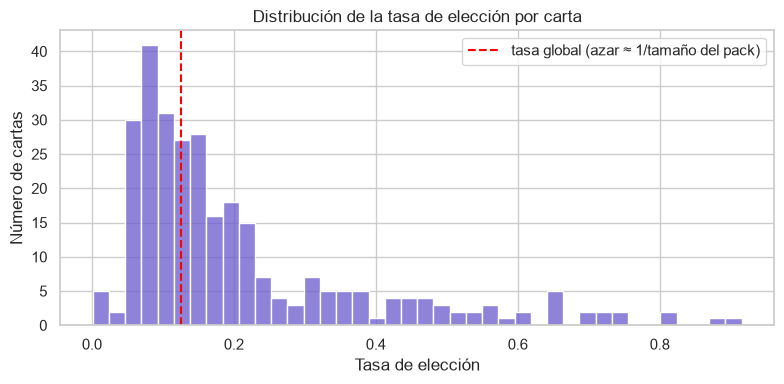

In [ ]:
tasa = X_train.groupby("carta")["y"].agg(tasa_eleccion="mean", apariciones="size")
tasa = tasa[tasa["apariciones"] >= 50].sort_values("tasa_eleccion", ascending=False)

print("Las 10 cartas con MAYOR tasa de elección:")
print(tasa.head(10).round(3).to_string())
print("\nLas 10 cartas con MENOR tasa de elección:")
print(tasa.tail(10).round(3).to_string())

plt.figure(figsize=(8, 4))
sns.histplot(tasa["tasa_eleccion"], bins=40, color="slateblue")
plt.axvline(X_train["y"].mean(), color="red", ls="--", label="tasa global (azar ≈ 1/tamaño del pack)")
plt.title("Distribución de la tasa de elección por carta")
plt.xlabel("Tasa de elección")
plt.ylabel("Número de cartas")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación — tasa de elección por carta

- **La identidad de la carta es muy informativa.** Hay cartas elegidas casi siempre que están disponibles (*Ajani Unrelenting* 91.5 %, *The Theorist, Jace Beleren* 88.1 %, *Lich's Relic* 82.1 %) y cartas casi ignoradas (comunes como *Charge the Sanctum* o *Artifist Acumen*, ≈ 4.6–5 %). Para ponerlo en perspectiva: la tasa global es 12.5 %, así que las cartas top se eligen ≈ 7 veces más de lo "esperado por azar".
- **Las cartas más elegidas aparecen pocas veces** (59 a 190 apariciones): son rares y míticas, que están en pocos packs. Las menos elegidas son comunes que aparecen miles de veces.
- **Los terrenos básicos (*Plains, Island, Swamp, Mountain, Forest*) casi nunca se eligen** (tasa 0.1–0.3 % con ≈ 7,100–7,300 apariciones cada uno). Son candidatas "fáciles" (el modelo aprende de inmediato a descartarlas); esto **infla ligeramente las métricas por pack**, sobre todo el Top-3 (limitación que se retoma en las conclusiones).
- Consecuencia para el modelado: la **línea base de popularidad** (recomendar la carta con mayor tasa de elección) será una referencia fuerte, y por eso es la que los modelos deben superar de forma clara.

## 5.2 Rareza, tipo y color

¿Los jugadores fuertes prefieren ciertas rarezas, tipos o colores?

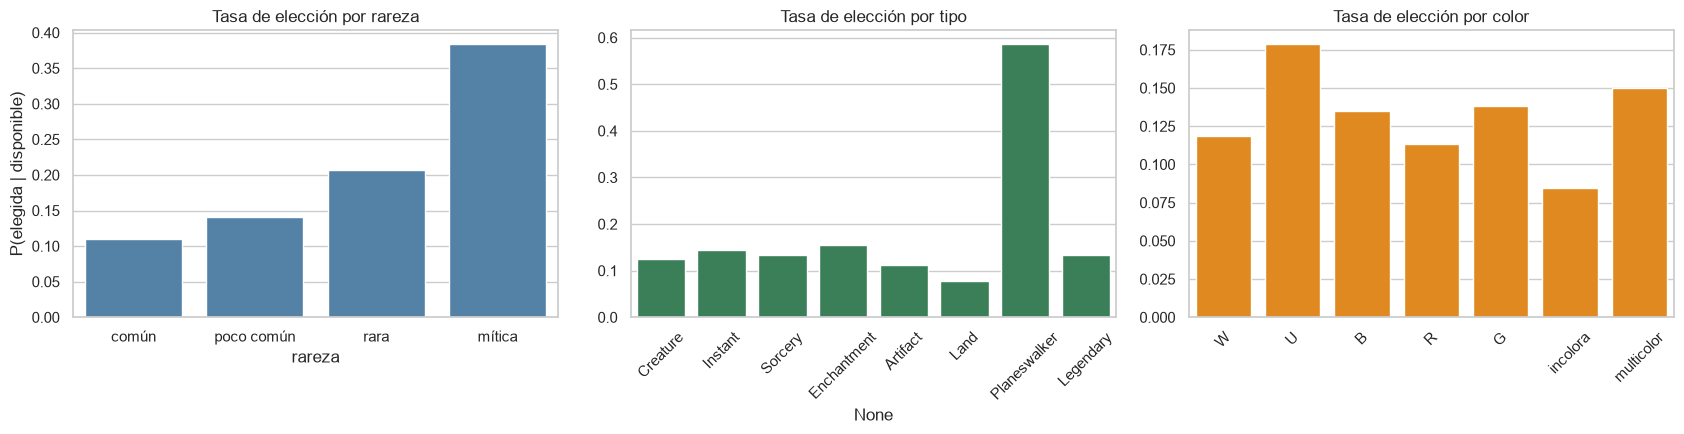

Tasa global de elección: 0.1251


In [ ]:
rar_nombre = {0: "común", 1: "poco común", 2: "rara", 3: "mítica"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

r = X_train.groupby("rareza")["y"].mean().rename(index=rar_nombre)
sns.barplot(x=r.index, y=r.values, ax=axes[0], color="steelblue")
axes[0].set_title("Tasa de elección por rareza"); axes[0].set_ylabel("P(elegida | disponible)")

tipos_cols = [f"tipo_{t}" for t in TIPOS]
t_rates = pd.Series({t: X_train.loc[X_train[f"tipo_{t}"] == 1, "y"].mean() for t in TIPOS})
sns.barplot(x=t_rates.index, y=t_rates.values, ax=axes[1], color="seagreen")
axes[1].set_title("Tasa de elección por tipo"); axes[1].tick_params(axis="x", rotation=45)

c_rates = {c: X_train.loc[X_train[f"color_{c}"] == 1, "y"].mean() for c in COLORES}
c_rates["incolora"] = X_train.loc[X_train["n_colores"] == 0, "y"].mean()
c_rates["multicolor"] = X_train.loc[X_train["n_colores"] >= 2, "y"].mean()
sns.barplot(x=list(c_rates.keys()), y=list(c_rates.values()), ax=axes[2], color="darkorange")
axes[2].set_title("Tasa de elección por color"); axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout(); plt.show()
print("Tasa global de elección:", round(X_train["y"].mean(), 4))

### Interpretación — rareza, tipo y color

- **Rareza:** la tasa de elección crece de forma monótona: común ≈ 11 %, poco común ≈ 14 %, rara ≈ 21 %, **mítica ≈ 38 %**. Una mítica se elige ≈ 3.5 veces más que una común. Por eso `rareza` y la posición relativa de rareza dentro del pack (`rareza_rank_pack`) son variables útiles.
- **Tipo:** los **Planeswalkers** destacan enormemente (≈ 58 % de las veces que aparecen se eligen); las tierras no básicas son las menos elegidas (≈ 8 %); criaturas, hechizos instantáneos/conjuros y encantamientos están entre 11 % y 16 %.
- **Color:** **azul** es el color más elegido (≈ 18 %) y rojo y blanco los menos (≈ 11–12 %); las multicolor ≈ 15 % y las incoloras ≈ 8.5 % (esta categoría incluye los terrenos básicos, que casi nunca se eligen). *Aviso:* las diferencias por color pueden deberse a que ciertos colores concentran más cartas de alto poder en este set, no solo a la "preferencia" de los jugadores.
- Aviso general: son tasas **marginales** (cada barra mezcla muchas cartas distintas); no equivalen a un efecto causal.

## 5.3 Compromiso con los colores a lo largo del draft

En Magic, los jugadores suelen **comprometerse con 2 colores** a medida que avanza el draft. Si esto ocurre, la **afinidad de color** entre una candidata y el pool será una variable decisiva. Se mide: *¿qué fracción de las cartas con color del pool pertenece a los 2 colores principales?*

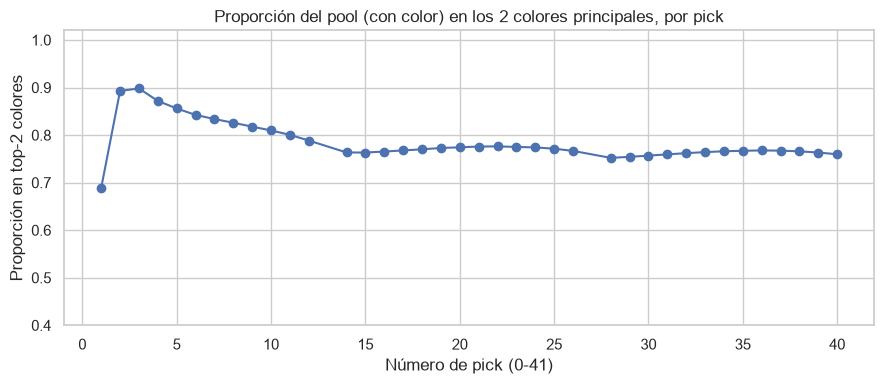

pick_global
1.0     0.689
6.0     0.842
11.0    0.800
22.0    0.776
33.0    0.764
40.0    0.760


In [12]:
# QUÉ HACE: para cada pick (una fila por pick), suma las 2 mayores proporciones de color del pool
# y promedia por número de pick global (0-41). Si el jugador se compromete con 2 colores, la curva sube y se acerca a 1.
cols_prop = [f"pool_prop_{c}" for c in COLORES]
por_pick = X_train.drop_duplicates("pick_id").copy()
por_pick["pick_global"] = por_pick["pack_number"] * 14 + por_pick["pick_number"]
sorted_prop = np.sort(por_pick[cols_prop].to_numpy(), axis=1)[:, ::-1]
por_pick["top2_share"] = sorted_prop[:, :2].sum(axis=1)
mask_c = por_pick["pool_n_con_color"] >= 3          # con al menos 3 cartas de color en el pool

curva = por_pick[mask_c].groupby("pick_global")["top2_share"].mean()
plt.figure(figsize=(9, 4))
plt.plot(curva.index, curva.values, marker="o")
plt.title("Proporción del pool (con color) en los 2 colores principales, por pick")
plt.xlabel("Número de pick (0-41)"); plt.ylabel("Proporción en top-2 colores")
plt.ylim(0.4, 1.02); plt.tight_layout(); plt.show()
print(curva.iloc[[0, 5, 10, 20, 30, -1]].round(3).to_string())

### Interpretación — compromiso con los colores

Se midió qué proporción de las cartas con color del pool pertenece a los 2 colores principales:

| Pick (global) | 1 | 6 | 11 | 22 | 33 | 40 |
|---|---|---|---|---|---|---|
| % en 2 colores principales | 68.9 % | **84.2 %** | 80.0 % | 77.6 % | 76.4 % | 76.0 % |

- **Sí hay compromiso de color rápido:** en cuanto se tienen unas pocas cartas con color (pick 6) ya ≈ 84 % del pool está en 2 colores. Esto justifica las variables de **afinidad de color** (`afinidad_color_media`, `afinidad_color_min`, `en_top2_colores`).
- **No es monótono:** después del pick 6 la proporción **baja** a ≈ 76 % al final. Explicaciones plausibles (no verificadas con los datos): jugadores que añaden un tercer color como "splash" y cartas multicolor (cuentan en dos colores a la vez), y que el pool de los últimos picks incluye cartas de relleno o de apuesta. Es decir, la afinidad de color es un **fuerte indicio, no una regla rígida**: el modelo debe poder elegir una carta fuera de color cuando es muy poderosa.

## 5.4 Dificultad según el tamaño del pack

Al inicio de cada ronda el pack tiene 14 cartas (elección difícil: azar ≈ 7 %); hacia el final quedan pocas (azar ≈ 33-50 %). Esto afecta cómo interpretar la exactitud por posición.

In [13]:
# QUÉ HACE: tamaño de pack por número de pick y exactitud esperada de un modelo ALEATORIO (= 1 / tamaño del pack).
azar = X_train.drop_duplicates("pick_id").groupby("pick_number")["tam_pack"].mean()
print(pd.DataFrame({"tam_pack": azar, "top1_azar": (1 / azar).round(3)}).T.round(3).to_string())
print(f"\nTop-1 de un modelo aleatorio sobre todo Train: "
      f"{(1 / X_train.groupby('pick_id')['tam_pack'].first()).mean():.3f}")

pick_number    0.0     1.0     2.0     3.0    4.0    5.0    6.0    7.0    8.0    9.0    10.0   11.0  12.0
tam_pack     13.990  12.989  11.992  10.993  9.992  8.995  7.996  6.996  5.997  4.998  3.999  3.000   2.0
top1_azar     0.071   0.077   0.083   0.091  0.100  0.111  0.125  0.143  0.167  0.200  0.250  0.333   0.5

Top-1 de un modelo aleatorio sobre todo Train: 0.173


## 5.5 Calidad de datos, valores faltantes y outliers

- **Nulos:** ninguno en la matriz de candidatas (las cartas sin datos de Scryfall reciben valores neutros).
- **Outliers:** las variables numéricas están acotadas por naturaleza (`cmc` 0-10, rareza 0-3, conteos del pool ≤ 45); no hay valores atípicos que eliminar.
- **Escala:** las variables tienen rangos muy distintos (`cmc` 0-10, proporciones 0-1, `pick_number` 0-13), por lo que se **estandarizan** dentro del `Pipeline` (necesario para regresión logística y SVM).
- **Colinealidad:** algunas variables están relacionadas por construcción (p. ej. `pool_size` con `pick_number`/`pack_number`); no es problema para árboles y se controla con regularización en los modelos lineales.

# VI. Preprocesamiento: Pipeline + ColumnTransformer

El preprocesamiento se encapsula en un `ColumnTransformer` que será la primera etapa de **cada** `Pipeline`:

- **Numéricas** (`COLS_NUMERICAS`, 46 variables) → `StandardScaler` (media 0, desviación 1).
- **Categórica `carta`** (295 valores) → `OneHotEncoder(handle_unknown="ignore")`, para que el modelo aprenda la calidad intrínseca de cada carta.
- **Resto de columnas** (`pick_id`, `draft_id`, `y`) → se descartan (`remainder="drop"`). *Nota:* `pick_id` y `draft_id` **viajan** dentro del DataFrame solo para poder calcular las métricas por pack y para agrupar la validación cruzada por draft; no entran como variables al modelo.

Al estar **dentro** del `Pipeline`, el escalador y el codificador se ajustan solo con el subconjunto de entrenamiento de cada fold, evitando fuga de información.

In [14]:
# QUÉ HACE: define el preprocesamiento y verifica su salida con Train (solo verificación).
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), COLS_NUMERICAS),
        ("carta", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CATEGORICAS),
    ],
    remainder="drop",
)

demo = preprocesador.fit_transform(X_train.sample(20000, random_state=RANDOM_STATE))
print(f"Variables numéricas: {len(COLS_NUMERICAS)} | categorías de 'carta': {len(nombres)}")
print(f"Matriz transformada (muestra de 20,000 filas): {demo.shape} | nulos: {int(np.isnan(demo).sum())}")

Variables numéricas: 46 | categorías de 'carta': 295
Matriz transformada (muestra de 20,000 filas): (20000, 341) | nulos: 0


# VII. Marco experimental común

**Muestras de trabajo.** Train tiene ≈ 630 mil filas candidatas; entrenar y optimizar 10 algoritmos con validación cruzada de 5 particiones sobre todo Train sería inviable en un equipo modesto (sobre todo SVM no lineal). Se trabaja en tres niveles, siempre tomando **picks completos** (con todas sus candidatas), nunca filas sueltas:

| Muestra | Picks | Uso |
|---|---|---|
| `N_PICKS_CV` | 6,000 | Validación cruzada y búsqueda de hiperparámetros de todos los modelos |
| `N_PICKS_SVM` | 2,000 | SVM polinomial y RBF (complejidad ~cuadrática en filas) |
| `N_PICKS_FINAL` | 30,000 | **Reentrenamiento final** de los 3 modelos seleccionados (con los hiperparámetros ya elegidos) antes de evaluarlos en Test |

**Validación cruzada.** `StratifiedGroupKFold` de 5 particiones, **agrupando por draft** (los picks de un mismo draft nunca quedan repartidos entre entrenamiento y validación de un fold) y conservando la proporción de clases.

**Métricas.**
- **Top-1 accuracy** (principal, fijada *antes* de ver Test): la carta elegida es la recomendada en 1.er lugar.
- **Top-3 accuracy:** la carta elegida está entre las 3 recomendadas (es lo que mostrará la aplicación).
- **ROC-AUC** a nivel de fila (calidad del ordenamiento candidata-vs-no elegida, independiente del umbral).
- Se registra también la métrica de **entrenamiento** para diagnosticar sobreajuste (brecha entrenamiento − validación).

**Cómo se calculan las métricas por pack dentro de la validación cruzada:** se pasa a scikit-learn una función *scorer* propia que, con las columnas `pick_id` del conjunto de validación, ordena las candidatas de cada pick por su puntaje y revisa si la elegida quedó entre las primeras.

In [ ]:
N_PICKS_CV, N_PICKS_SVM, N_PICKS_FINAL = 6000, 2000, 30000

def muestrear_picks(X, n, semilla=RANDOM_STATE):
    pids = X["pick_id"].unique()
    elegidos = np.random.RandomState(semilla).choice(pids, size=min(n, len(pids)), replace=False)
    return X[X["pick_id"].isin(elegidos)].reset_index(drop=True)

def _topk(est, X, y, k):
    s = puntaje(est, X)
    d = pd.DataFrame({"pid": X["pick_id"].to_numpy(), "s": s, "y": np.asarray(y)})
    d["rk"] = d.groupby("pid")["s"].rank(ascending=False, method="first")
    return float((d.loc[d["y"] == 1, "rk"] <= k).mean())

def top1_scorer(est, X, y):
    return _topk(est, X, y, 1)

def top3_scorer(est, X, y):
    return _topk(est, X, y, 3)

X_cv = muestrear_picks(X_train, N_PICKS_CV)
X_svm = muestrear_picks(X_train, N_PICKS_SVM)
print(f"Muestra CV : {len(X_cv):,} candidatas / {X_cv['pick_id'].nunique():,} picks / {X_cv['draft_id'].nunique():,} drafts")
print(f"Muestra SVM: {len(X_svm):,} candidatas / {X_svm['pick_id'].nunique():,} picks")

Muestra CV : 47,761 candidatas / 6,000 picks / 1,947 drafts
Muestra SVM: 15,832 candidatas / 2,000 picks


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC

cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"top1": top1_scorer, "top3": top3_scorer, "roc_auc": "roc_auc"}
resultados = []

def _registrar(nombre, familia, tipo, m):
    resultados.append({"Modelo": nombre, "Familia": familia, "Tipo": tipo, **m})
    print(f"{nombre}: top1 val={m['Top1_val']:.4f} (+-{m['Top1_std']:.4f}) | top3={m['Top3_val']:.4f} | "
          f"AUC={m['AUC_val']:.4f} | top1 train={m['Top1_train']:.4f} | {m['Tiempo_s']:.0f}s")

def evaluar_base(nombre, familia, estimador, X):
    t0 = time.time()
    pipe = Pipeline([("prep", preprocesador), ("modelo", estimador)])
    r = cross_validate(pipe, X, X["y"], groups=X["draft_id"], cv=cv5, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    _registrar(nombre, familia, "Base", {
        "Top1_val": r["test_top1"].mean(), "Top1_std": r["test_top1"].std(), "Top3_val": r["test_top3"].mean(),
        "AUC_val": r["test_roc_auc"].mean(), "Top1_train": r["train_top1"].mean(), "Tiempo_s": time.time() - t0})

def evaluar_busqueda(nombre, familia, estimador, rejilla, X, random_n=None):
    t0 = time.time()
    pipe = Pipeline([("prep", preprocesador), ("modelo", estimador)])
    kw = dict(cv=cv5, scoring=SCORING, refit="top1", return_train_score=True, n_jobs=-1)
    bus = (RandomizedSearchCV(pipe, rejilla, n_iter=random_n, random_state=RANDOM_STATE, **kw) if random_n
           else GridSearchCV(pipe, rejilla, **kw))
    bus.fit(X, X["y"], groups=X["draft_id"])
    i, res = bus.best_index_, bus.cv_results_
    print(f"{nombre}: mejores parámetros = {bus.best_params_}")
    _registrar(nombre, familia, "Optimizado", {
        "Top1_val": res["mean_test_top1"][i], "Top1_std": res["std_test_top1"][i], "Top3_val": res["mean_test_top3"][i],
        "AUC_val": res["mean_test_roc_auc"][i], "Top1_train": res["mean_train_top1"][i], "Tiempo_s": time.time() - t0})
    return bus

### Líneas base de referencia (sin aprendizaje)

Antes de entrenar, conviene saber qué se logra **sin machine learning**; un modelo debe superar estas referencias para justificarse:

- **Azar:** elegir una candidata al azar (top-1 esperado = promedio de 1/tamaño del pack).
- **Popularidad:** recomendar la carta con **mayor tasa de elección histórica** (calculada con Train). Es la heurística "tier list" más natural.
- **Rareza:** recomendar la de mayor rareza del pack.

In [17]:
# QUÉ HACE: evalúa las 3 líneas base en la muestra CV (ya está solo Train; Test sigue sin usarse).
# La tasa de elección por carta se calcula con TODO Train; para Test se usará la misma tabla (sección XIII).
tasa_train = X_train.groupby("carta")["y"].mean()

def topk_desde_puntaje(X, s, k):
    d = pd.DataFrame({"pid": X["pick_id"].to_numpy(), "s": np.asarray(s), "y": X["y"].to_numpy()})
    d["rk"] = d.groupby("pid")["s"].rank(ascending=False, method="first")
    return float((d.loc[d["y"] == 1, "rk"] <= k).mean())

ale = np.random.RandomState(RANDOM_STATE).rand(len(X_cv))
lineas_base = {
    "Azar": ale,
    "Popularidad (tasa de elección histórica)": X_cv["carta"].map(tasa_train).fillna(0).to_numpy(),
    "Rareza (la más rara del pack)": X_cv["rareza"].to_numpy() + 0.01 * ale,
}
tabla_lb = pd.DataFrame({n: {"Top-1": topk_desde_puntaje(X_cv, s, 1), "Top-3": topk_desde_puntaje(X_cv, s, 3)}
                         for n, s in lineas_base.items()}).T
tabla_lb.round(4)

,Top-1,Top-3
Azar,0.1710,0.4730
Popularidad (tasa de elección histórica),0.4520,0.8062
Rareza (la más rara del pack),0.2482,0.5697


### Interpretación — líneas base (muestra CV de 6,000 picks)

| Línea base | Top-1 | Top-3 |
|---|---|---|
| Azar | 17.1 % | 47.3 % |
| Rareza (la más rara del pack) | 24.8 % | 57.0 % |
| **Popularidad** (tasa de elección histórica) | **45.2 %** | **80.6 %** |

- Elegir la carta de mayor rareza ya duplica al azar en Top-3 pero sigue lejos de un buen resultado; la **popularidad es la referencia seria**: con una sola tabla de tasas se acierta casi la mitad de los picks.
- Un modelo de machine learning solo se justifica si **supera claramente a la popularidad**; si no, bastaría con una "tier list". Esta es la vara con la que se evalúan todos los modelos siguientes.
- Nota metodológica: las tasas de popularidad se calculan con todo Train, que incluye a la muestra CV, por lo que esta referencia es *ligeramente optimista* para esa muestra (en Test, sección XIII, se usa con datos realmente no vistos).

# VIII. (A) Regresión Logística — base y optimizada

La **Regresión Logística** estima la probabilidad de que una candidata sea la elegida como una función sigmoide de una combinación lineal de las variables (incluidas las 295 de identidad de carta). Es rápida, interpretable y sirve de **línea base de modelado**.

- **Base:** parámetros por defecto (L2, `C = 1`).
- **Optimizada:** `GridSearchCV` sobre `C` (regularización: menor = más fuerte), `penalty` (L1 elimina variables, L2 las encoge) y `class_weight` (`None` vs. `balanced`, por el desbalance 1:7).

In [ ]:
evaluar_base("Regresión Logística (base)", "Lineal", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), X_cv)

bus_lr = evaluar_busqueda(
    "Regresión Logística (optimizada)", "Lineal",
    LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE),
    {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1], "modelo__penalty": ["l1", "l2"],
     "modelo__class_weight": [None, "balanced"]},
    X_cv)

Regresión Logística (base): top1 val=0.5635 (+-0.0122) | top3=0.8788 | AUC=0.8738 | top1 train=0.5869 | 35s
Regresión Logística (optimizada): mejores parámetros = {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__penalty': 'l2'}
Regresión Logística (optimizada): top1 val=0.5632 (+-0.0120) | top3=0.8783 | AUC=0.8739 | top1 train=0.5879 | 1408s


Coeficientes exactamente 0 (eliminados por L1, si aplica): 0 de 341


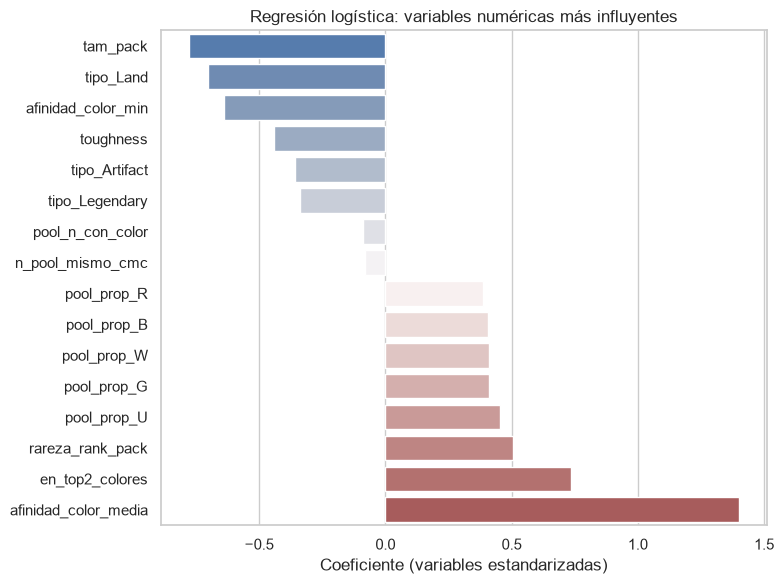


Cartas con coeficiente más alto (se eligen más, a igual contexto):
Mindseeker Oculus          2.468
No Admittance              2.487
Kiora of Fire and Ashes    2.767
Last Gasp                  2.772
Extended Absence           2.827
Lich's Relic               2.993

Cartas con coeficiente más bajo:
Entrust the Spark   -3.254
Mountain            -3.046
Swamp               -2.980
Forest              -2.955
Island              -2.687
Precise Redaction   -2.559


In [ ]:

modelo_lr = bus_lr.best_estimator_
nom_vars = modelo_lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modelo_lr.named_steps["modelo"].coef_[0], index=nom_vars)
print(f"Coeficientes exactamente 0 (eliminados por L1, si aplica): {(coefs == 0).sum()} de {len(coefs)}")

solo_num = coefs[coefs.index.str.startswith("num__")].sort_values()
etq = [n.replace("num__", "") for n in solo_num.index]
top = pd.concat([solo_num.head(8), solo_num.tail(8)])
etq = [n.replace("num__", "") for n in top.index]
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=etq, hue=etq, palette="vlag", legend=False)
plt.title("Regresión logística: variables numéricas más influyentes")
plt.xlabel("Coeficiente (variables estandarizadas)")
plt.tight_layout(); plt.show()

carta_coefs = coefs[coefs.index.str.startswith("carta__")].sort_values()
print("\nCartas con coeficiente más alto (se eligen más, a igual contexto):")
print(carta_coefs.tail(6).rename(lambda n: n.replace("carta__carta_", "")).round(3).to_string())
print("\nCartas con coeficiente más bajo:")
print(carta_coefs.head(6).rename(lambda n: n.replace("carta__carta_", "")).round(3).to_string())

### Interpretación — Regresión Logística

**Desempeño.** Base: Top-1 = **0.5635** (±0.0122), Top-3 = 0.8788, AUC = 0.8738. Optimizada: Top-1 = 0.5632, Top-3 = 0.8783, AUC = 0.8739. **La optimización no aportó nada**: los mejores parámetros (`C = 1`, penalización L2, sin `class_weight`) son prácticamente los valores por defecto. `C = 1` es además el **extremo superior de la rejilla** → el modelo "pide" muy poca regularización, algo razonable porque hay ≈ 47 mil filas para solo 341 variables (poco riesgo de sobreajuste: brecha entrenamiento−validación = 0.025). Ya supera con claridad a la línea base de popularidad (0.452) en ≈ 11 puntos porcentuales. (Su tiempo de búsqueda, ≈ 1,400 s, se debe a que `liblinear` converge lento con `C` altos y 24 combinaciones × 5 folds, no al modelo en sí.)

**Qué aprendió (coeficientes, variables estandarizadas).**
- Las variables de **encaje con el pool** dominan: `afinidad_color_media` (**+1.40**), `en_top2_colores` (+0.73) y `rareza_rank_pack` (+0.50). Es decir: se elige lo que combina con los colores que ya llevas y lo más raro del pack.
- `tipo_Land` (−0.70): las tierras (sobre todo las básicas) casi no se eligen.
- **Cuidado con los signos individuales:** `afinidad_color_min` sale *negativa* (−0.65) a pesar de ser también una medida de afinidad. Es un efecto de **colinealidad** (está muy correlacionada con `afinidad_color_media`): el modelo reparte el efecto entre las dos y el signo de cada una por separado no es interpretable; lo que importa es su efecto conjunto.
- `tam_pack` (−0.78) y `pool_prop_*` valen **lo mismo para todas las candidatas de un pack**: en un modelo lineal desplazan por igual a todas las cartas del pack y **no cambian el orden** (solo la probabilidad absoluta). Sirven al modelo para calibrar, y son útiles de verdad en los modelos no lineales.
- **Cartas:** coeficientes altos para *Lich's Relic* (+2.99), *Extended Absence* (+2.83), *Last Gasp* (+2.77), *Kiora of Fire and Ashes* (+2.77); bajos para los terrenos básicos (≈ −2.7 a −3.0), *Entrust the Spark* (−3.25) y *Precise Redaction* (−2.56). Los coeficientes de estas cartas son grandes porque la regularización es débil y cada carta es una columna One-Hot; su magnitud es relativa, no una "probabilidad".

# IX. (B) Máquinas de Vectores de Soporte (SVM)

Una **SVM** busca el hiperplano que separa las clases con mayor margen; con *kernels* puede hacerlo en espacios de mayor dimensión sin construirlos explícitamente:

- **Lineal** (`LinearSVC`): escala bien; entrenada con la muestra CV.
- **Polinomial** y **RBF** (`SVC`): fronteras no lineales; su costo crece aproximadamente de forma **cuadrática** con el número de filas, por lo que se entrenan y optimizan con la muestra reducida `X_svm` (2,000 picks ≈ 15 mil filas). Para una comparación justa se evalúa también una **Regresión Logística sobre esa misma muestra**.

In [ ]:
evaluar_base("Reg. Logística base (muestra SVM)", "Referencia", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), X_svm)

evaluar_base("SVM lineal (base)", "SVM", LinearSVC(max_iter=20000, random_state=RANDOM_STATE), X_cv)
bus_svm_lin = evaluar_busqueda(
    "SVM lineal (optimizada)", "SVM", LinearSVC(max_iter=20000, random_state=RANDOM_STATE),
    {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3], "modelo__class_weight": [None, "balanced"]}, X_cv)

Reg. Logística base (muestra SVM): top1 val=0.5305 (+-0.0206) | top3=0.8655 | AUC=0.8613 | top1 train=0.5875 | 6s
SVM lineal (base): top1 val=0.5613 (+-0.0131) | top3=0.8835 | AUC=0.8734 | top1 train=0.5893 | 22s
SVM lineal (optimizada): mejores parámetros = {'modelo__C': 0.3, 'modelo__class_weight': None}
SVM lineal (optimizada): top1 val=0.5638 (+-0.0143) | top3=0.8837 | AUC=0.8738 | top1 train=0.5887 | 127s


In [ ]:
# degree = grado del polinomio (orden de las interacciones), C = regularización,
# coef0 = término independiente del kernel, gamma = escala del producto interno.
evaluar_base("SVM polinomial (base)", "SVM", SVC(kernel="poly", random_state=RANDOM_STATE), X_svm)
bus_svm_poly = evaluar_busqueda(
    "SVM polinomial (optimizada)", "SVM", SVC(kernel="poly", random_state=RANDOM_STATE),
    {"modelo__degree": [2, 3], "modelo__C": [0.1, 1], "modelo__coef0": [1], "modelo__gamma": ["scale"]}, X_svm)

SVM polinomial (base): top1 val=0.4245 (+-0.0174) | top3=0.7730 | AUC=0.7922 | top1 train=0.7866 | 298s
SVM polinomial (optimizada): mejores parámetros = {'modelo__C': 1, 'modelo__coef0': 1, 'modelo__degree': 2, 'modelo__gamma': 'scale'}
SVM polinomial (optimizada): top1 val=0.4965 (+-0.0152) | top3=0.8335 | AUC=0.8391 | top1 train=0.6381 | 835s


In [ ]:
# gamma bajo = frontera suave; gamma alto = frontera muy flexible (riesgo de sobreajuste).
evaluar_base("SVM RBF (base)", "SVM", SVC(kernel="rbf", random_state=RANDOM_STATE), X_svm)
bus_svm_rbf = evaluar_busqueda(
    "SVM RBF (optimizada)", "SVM", SVC(kernel="rbf", random_state=RANDOM_STATE),
    {"modelo__C": [0.1, 0.3, 1, 3, 10], "modelo__gamma": [0.0003, 0.001, 0.003, "scale"],
     "modelo__class_weight": [None, "balanced"]}, X_svm, random_n=8)

SVM RBF (base): top1 val=0.4805 (+-0.0167) | top3=0.8160 | AUC=0.8321 | top1 train=0.8124 | 214s
SVM RBF (optimizada): mejores parámetros = {'modelo__gamma': 0.0003, 'modelo__class_weight': None, 'modelo__C': 1}
SVM RBF (optimizada): top1 val=0.5205 (+-0.0220) | top3=0.8485 | AUC=0.8499 | top1 train=0.6190 | 2460s


### Interpretación — SVM

| Modelo | Top-1 base → optimizada | AUC (opt.) | Brecha (opt.) |
|---|---|---|---|
| SVM lineal (muestra CV, 6,000 picks) | 0.5613 → **0.5638** | 0.8738 | 0.025 |
| SVM polinomial (muestra SVM, 2,000 picks) | 0.4245 → 0.4965 | 0.8391 | 0.142 |
| SVM RBF (muestra SVM, 2,000 picks) | 0.4805 → 0.5205 | 0.8499 | 0.099 |
| *Referencia: Reg. Logística con la misma muestra de 2,000 picks* | 0.5305 | 0.8613 | 0.057 |

1. **SVM lineal ≈ Regresión Logística** (0.5638 vs. 0.5632; la diferencia, 0.0006, es 20 veces menor que la desviación entre folds ≈ 0.014): ambos son modelos lineales regularizados y solo cambia la función de pérdida.
2. **Los kernels no lineales no superan al modelo lineal con los mismos datos.** Con la misma muestra de 2,000 picks, la regresión logística (0.5305) supera a la SVM polinomial (0.4965) por 3.4 puntos y a la RBF (0.5205) por 1 punto (esta última dentro del ruido, ±0.022). La **ingeniería de variables ya codifica de forma explícita las interacciones carta × pool** (afinidad de color, curva...), por lo que un kernel no lineal tiene poco que añadir.
3. **Sobreajuste:** los modelos base de ambos kernels memorizan (Top-1 de entrenamiento 0.79 y 0.81 vs. 0.42 y 0.48 en validación). La optimización ayuda mucho (+0.072 el polinomial, +0.040 el RBF) pero sigue habiendo brecha (0.14 y 0.10). Los hiperparámetros óptimos del RBF (`gamma = 0.0003`, el **valor más bajo de la rejilla**) indican que prefiere una frontera casi lineal: es otra señal de que no hay estructura no lineal fuerte que explotar.
4. **Más datos importan:** la misma regresión logística pasa de 0.5305 (2,000 picks) a 0.5635 (6,000 picks): +3.3 puntos. Por eso al final se reentrenan los 3 modelos elegidos con 30,000 picks.
5. **Costo:** la SVM RBF tardó ≈ 41 minutos y la polinomial ≈ 14, con 3 veces menos datos que la lineal (≈ 2 minutos).

# X. (C) Random Forest

Un **Random Forest** entrena muchos árboles sobre muestras *bootstrap* y con subconjuntos aleatorios de variables, y promedia sus votos. Captura **interacciones no lineales** (p. ej. "esta carta vale mucho *si* ya tengo cartas de su color") sin necesitar escalado. Hiperparámetros optimizados con `RandomizedSearchCV`: `n_estimators`, `max_depth`, `min_samples_leaf` (controlan complejidad y sobreajuste) y `max_features`.

In [23]:
# QUÉ HACE: Random Forest base y optimizado (RandomizedSearchCV, 6 combinaciones).
# n_jobs=1 en el modelo porque el paralelismo ya lo hace la validación cruzada (n_jobs=-1 en la búsqueda).
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier, StackingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from xgboost import XGBClassifier

evaluar_base("Random Forest (base)", "Árboles/Ensamble",
             RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1), X_cv)
bus_rf = evaluar_busqueda(
    "Random Forest (optimizado)", "Árboles/Ensamble", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    {"modelo__n_estimators": [100, 200], "modelo__max_depth": [8, 12, 20],
     "modelo__min_samples_leaf": [5, 20, 50], "modelo__max_features": ["sqrt", 0.2]},
    X_cv, random_n=6)

Random Forest (base): top1 val=0.5257 (+-0.0121) | top3=0.8543 | AUC=0.8589 | top1 train=0.9999 | 42s
Random Forest (optimizado): mejores parámetros = {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.2, 'modelo__max_depth': 20}
Random Forest (optimizado): top1 val=0.5185 (+-0.0153) | top3=0.8585 | AUC=0.8628 | top1 train=0.9107 | 613s


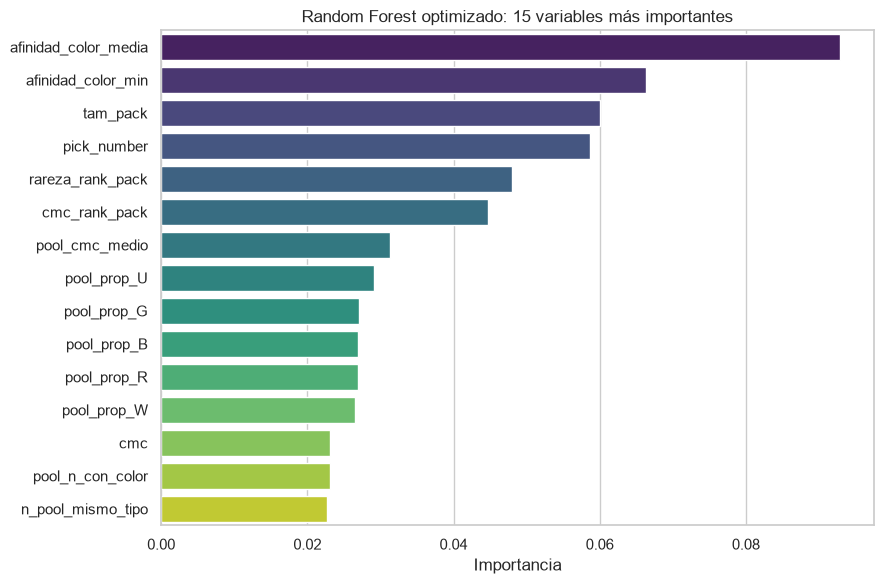

In [24]:
# QUÉ HACE: importancia de variables del Random Forest (reducción media de impureza).
# Cuidado: favorece variables con muchos valores distintos; es una señal cualitativa.
rf_fit = bus_rf.best_estimator_
nom_rf = rf_fit.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_fit.named_steps["modelo"].feature_importances_, index=nom_rf).sort_values(ascending=False).head(15)
etq = [n.replace("num__", "").replace("carta__carta_", "carta: ") for n in imp.index]
plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=etq, hue=etq, palette="viridis", legend=False)
plt.title("Random Forest optimizado: 15 variables más importantes")
plt.xlabel("Importancia")
plt.tight_layout(); plt.show()

### Interpretación — Random Forest

- **Sobreajuste extremo:** el bosque base tiene Top-1 de entrenamiento = **0.9999** y de validación = 0.5257 (brecha **0.47**): memoriza el entrenamiento. El optimizado (200 árboles, `max_depth = 20`, `min_samples_leaf = 5`, `max_features = 0.2`) baja el entrenamiento a 0.9108 pero sigue con brecha 0.39.
- **La optimización no mejoró el Top-1** (0.5257 → 0.5185, una diferencia de −0.007 que es **la mitad de la desviación entre folds**, ±0.015, es decir, ruido). Sí mejoró ligeramente Top-3 (0.8543 → 0.8585) y AUC (0.8589 → 0.8628). La búsqueda aleatoria probó solo 6 combinaciones, y la configuración por defecto no estaba entre ellas; es un recordatorio de que **optimizar con pocas combinaciones puede no superar a los valores por defecto**. Además, varios hiperparámetros quedaron en un borde de la rejilla (`max_depth = 20`, `min_samples_leaf = 5`).
- **Importancia de variables:** dominan `afinidad_color_media` (≈ 0.093) y `afinidad_color_min` (≈ 0.066), seguidas de `tam_pack`, `pick_number`, `rareza_rank_pack` y `cmc_rank_pack` (≈ 0.045–0.060), y luego las proporciones de color del pool. Es **coherente con la regresión logística** (el encaje de color es lo más importante). Las columnas de identidad de carta no aparecen individualmente porque la importancia se **reparte entre 295 columnas One-Hot** (efecto de dilución), no porque no importen.
- En este problema el RF queda por debajo de los modelos lineales (0.5185 vs. 0.5632): con variables ya muy elaboradas y 295 columnas One-Hot dispersas, los árboles aprovechan peor la información que un modelo lineal.

# XI. (D) Métodos de ensamble

- **AdaBoost:** árboles muy simples (*stumps*) en secuencia; cada uno se concentra en los errores del anterior.
- **Gradient Boosting:** árboles secuenciales que corrigen el error residual del conjunto.
- **XGBoost:** implementación regularizada y eficiente de Gradient Boosting.
- **Voting (soft):** promedia las probabilidades de varios modelos distintos (Regresión Logística + Random Forest + Gradient Boosting).
- **Stacking:** un meta-modelo (regresión logística) aprende a combinar las predicciones fuera de muestra (`cv=3`) de esos mismos modelos base.

Para limitar el costo, los grids son pequeños y los ensambles base usan configuraciones moderadas.

In [25]:
# QUÉ HACE: AdaBoost. Cada stump nuevo pesa más los ejemplos que los anteriores clasificaron mal.
# learning_rate reduce la contribución de cada árbol.
evaluar_base("AdaBoost (base)", "Ensamble", AdaBoostClassifier(random_state=RANDOM_STATE), X_cv)
bus_ada = evaluar_busqueda(
    "AdaBoost (optimizado)", "Ensamble", AdaBoostClassifier(random_state=RANDOM_STATE),
    {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.3, 1.0]}, X_cv)

AdaBoost (base): top1 val=0.4067 (+-0.0188) | top3=0.7803 | AUC=0.7976 | top1 train=0.4081 | 63s
AdaBoost (optimizado): mejores parámetros = {'modelo__learning_rate': 1.0, 'modelo__n_estimators': 200}
AdaBoost (optimizado): top1 val=0.4263 (+-0.0192) | top3=0.7925 | AUC=0.8099 | top1 train=0.4287 | 653s


In [26]:
# QUÉ HACE: Gradient Boosting de scikit-learn. subsample=0.5 y max_features="sqrt" reducen el costo
# y actúan como regularización (aleatoriedad).
evaluar_base("Gradient Boosting (base)", "Ensamble",
             GradientBoostingClassifier(n_estimators=100, subsample=0.5, max_features="sqrt", random_state=RANDOM_STATE), X_cv)
bus_gb = evaluar_busqueda(
    "Gradient Boosting (optimizado)", "Ensamble",
    GradientBoostingClassifier(subsample=0.5, max_features="sqrt", random_state=RANDOM_STATE),
    {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.05, 0.1], "modelo__max_depth": [3, 4]},
    X_cv, random_n=6)

Gradient Boosting (base): top1 val=0.4802 (+-0.0073) | top3=0.8370 | AUC=0.8415 | top1 train=0.5062 | 10s
Gradient Boosting (optimizado): mejores parámetros = {'modelo__n_estimators': 200, 'modelo__max_depth': 4, 'modelo__learning_rate': 0.1}
Gradient Boosting (optimizado): top1 val=0.5280 (+-0.0131) | top3=0.8620 | AUC=0.8639 | top1 train=0.5998 | 83s


In [27]:
# QUÉ HACE: XGBoost. subsample/colsample_bytree = fracción de filas/columnas por árbol; reg_lambda = penalización L2.
# tree_method="hist" = algoritmo rápido basado en histogramas. n_jobs=1 por el mismo motivo que en el Random Forest.
evaluar_base("XGBoost (base)", "Ensamble",
             XGBClassifier(n_estimators=200, tree_method="hist", eval_metric="logloss", n_jobs=1, random_state=RANDOM_STATE), X_cv)
bus_xgb = evaluar_busqueda(
    "XGBoost (optimizado)", "Ensamble",
    XGBClassifier(tree_method="hist", eval_metric="logloss", n_jobs=1, random_state=RANDOM_STATE),
    {"modelo__n_estimators": [150, 300], "modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [3, 5],
     "modelo__subsample": [0.7, 1.0], "modelo__colsample_bytree": [0.5, 0.8], "modelo__reg_lambda": [1, 10]},
    X_cv, random_n=10)

XGBoost (base): top1 val=0.5470 (+-0.0145) | top3=0.8912 | AUC=0.8784 | top1 train=0.8245 | 21s
XGBoost (optimizado): mejores parámetros = {'modelo__subsample': 1.0, 'modelo__reg_lambda': 1, 'modelo__n_estimators': 300, 'modelo__max_depth': 5, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.8}
XGBoost (optimizado): top1 val=0.5482 (+-0.0147) | top3=0.8842 | AUC=0.8776 | top1 train=0.6810 | 214s


In [28]:
# QUÉ HACE: Voting (promedio ponderado de probabilidades) y Stacking (meta-modelo logístico sobre predicciones fuera de muestra).
# voting="soft" promedia probabilidades; weights se optimiza. final_estimator__C regulariza el meta-modelo.
lr_v = LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOM_STATE)
rf_v = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, max_features="sqrt",
                              random_state=RANDOM_STATE, n_jobs=1)
gb_v = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, subsample=0.5,
                                  max_features="sqrt", random_state=RANDOM_STATE)

evaluar_base("Voting soft (base)", "Ensamble",
             VotingClassifier([("lr", lr_v), ("rf", rf_v), ("gb", gb_v)], voting="soft"), X_cv)
bus_vot = evaluar_busqueda(
    "Voting soft (optimizado)", "Ensamble", VotingClassifier([("lr", lr_v), ("rf", rf_v), ("gb", gb_v)], voting="soft"),
    {"modelo__weights": [[1, 1, 1], [2, 1, 1], [2, 1, 2], [1, 0, 1]]}, X_cv)

evaluar_base("Stacking (base)", "Ensamble",
             StackingClassifier([("lr", lr_v), ("rf", rf_v), ("gb", gb_v)],
                                final_estimator=LogisticRegression(max_iter=3000), cv=3), X_cv)
bus_stk = evaluar_busqueda(
    "Stacking (optimizado)", "Ensamble",
    StackingClassifier([("lr", lr_v), ("rf", rf_v), ("gb", gb_v)], final_estimator=LogisticRegression(max_iter=3000), cv=3),
    {"modelo__final_estimator__C": [0.01, 0.1, 1.0]}, X_cv)

Voting soft (base): top1 val=0.5215 (+-0.0065) | top3=0.8560 | AUC=0.8597 | top1 train=0.5502 | 37s
Voting soft (optimizado): mejores parámetros = {'modelo__weights': [2, 1, 1]}
Voting soft (optimizado): top1 val=0.5305 (+-0.0091) | top3=0.8592 | AUC=0.8629 | top1 train=0.5555 | 150s
Stacking (base): top1 val=0.5315 (+-0.0125) | top3=0.8573 | AUC=0.8621 | top1 train=0.5621 | 86s
Stacking (optimizado): mejores parámetros = {'modelo__final_estimator__C': 1.0}
Stacking (optimizado): top1 val=0.5315 (+-0.0125) | top3=0.8573 | AUC=0.8621 | top1 train=0.5621 | 333s


### Interpretación — Ensambles

| Modelo | Top-1 base → optimizado | Brecha (opt.) | Comentario |
|---|---|---|---|
| AdaBoost | 0.4067 → 0.4263 (+0.020) | 0.002 | **Subajuste**: Top-1 de entrenamiento (0.4287) ≈ validación (0.4263), ambos bajos. Los *stumps* son demasiado simples y el óptimo está en el borde de la rejilla (`learning_rate = 1.0`). |
| Gradient Boosting | 0.4802 → 0.5280 (**+0.048**) | 0.072 | La optimización (200 árboles, profundidad 4) ayuda mucho: el modelo base estaba subajustado. |
| XGBoost | 0.5470 → **0.5482** (+0.001) | 0.133 | El mejor modelo no lineal. La base sobreajusta (entrenamiento 0.8245, brecha 0.28) y la regularización la reduce a 0.13 sin cambiar el Top-1. En Top-3 y AUC la versión base fue ligeramente mejor (0.8912 / 0.8784 vs. 0.8842 / 0.8776): empate práctico. |
| Voting (soft) | 0.5215 → 0.5305 (+0.009) | 0.025 | Pesos óptimos [2, 1, 1]: la regresión logística recibe doble peso. |
| Stacking | 0.5315 → 0.5315 (0) | 0.031 | Los mejores parámetros coinciden con el valor por defecto (`C = 1`). |

**Lectura global:** ningún ensamble supera a la regresión logística (0.5632). XGBoost queda a ≈ 1.5 puntos (≈ 1 desviación entre folds); Voting y Stacking, a ≈ 3 puntos, porque **combinan a la regresión logística con un Random Forest y un Gradient Boosting más débiles**: promediar con modelos peores no mejora al mejor, sobre todo cuando sus errores están correlacionados (todos usan las mismas variables). El **boosting con regularización** (XGBoost) es la única familia no lineal competitiva.

# XII. Comparación de modelos y selección

Se resumen todos los resultados de validación cruzada (5 folds, agrupados por draft). La **brecha de sobreajuste** es `Top1_train − Top1_val`: brecha grande = el modelo memoriza el entrenamiento; ambas métricas bajas y cercanas = subajuste.

In [ ]:
tabla = pd.DataFrame(resultados)
tabla["Brecha_top1"] = tabla["Top1_train"] - tabla["Top1_val"]
tabla = tabla.sort_values("Top1_val", ascending=False).reset_index(drop=True)
cols = ["Modelo", "Tipo", "Top1_val", "Top1_std", "Top3_val", "AUC_val", "Top1_train", "Brecha_top1", "Tiempo_s"]
display(tabla[cols].round(4))

,Modelo,Tipo,Top1_val,Top1_std,Top3_val,AUC_val,Top1_train,Brecha_top1,Tiempo_s
0,SVM lineal (optimizada),Optimizado,0.5638,0.0143,0.8837,0.8738,0.5888,0.0249,127.0531
1,Regresión Logística (base),Base,0.5635,0.0122,0.8788,0.8738,0.5869,0.0234,34.7070
2,Regresión Logística (optimizada),Optimizado,0.5632,0.0120,0.8783,0.8739,0.5879,0.0248,1407.7953
3,SVM lineal (base),Base,0.5613,0.0131,0.8835,0.8734,0.5893,0.0280,22.4700
4,XGBoost (optimizado),Optimizado,0.5482,0.0147,0.8842,0.8776,0.6810,0.1328,213.5818
5,XGBoost (base),Base,0.5470,0.0145,0.8912,0.8784,0.8245,0.2775,21.3750
6,Stacking (optimizado),Optimizado,0.5315,0.0125,0.8573,0.8621,0.5621,0.0306,333.2740
7,Stacking (base),Base,0.5315,0.0125,0.8573,0.8621,0.5621,0.0306,85.9918
8,Reg. Logística base (muestra SVM),Base,0.5305,0.0206,0.8655,0.8613,0.5875,0.0570,6.4580
9,Voting soft (optimizado),Optimizado,0.5305,0.0091,0.8592,0.8629,0.5555,0.0250,150.2035


Tipo,Base,Optimizado,Mejora
Algoritmo,,,
SVM lineal,0.5613,0.5638,0.0025
Regresión Logística,0.5635,0.5632,-0.0003
XGBoost,0.5470,0.5482,0.0012
Stacking,0.5315,0.5315,0.0000
Voting soft,0.5215,0.5305,0.0090
Gradient Boosting,0.4802,0.5280,0.0478
SVM RBF,0.4805,0.5205,0.0400
Random Forest,0.5257,0.5185,-0.0072
SVM polinomial,0.4245,0.4965,0.0720


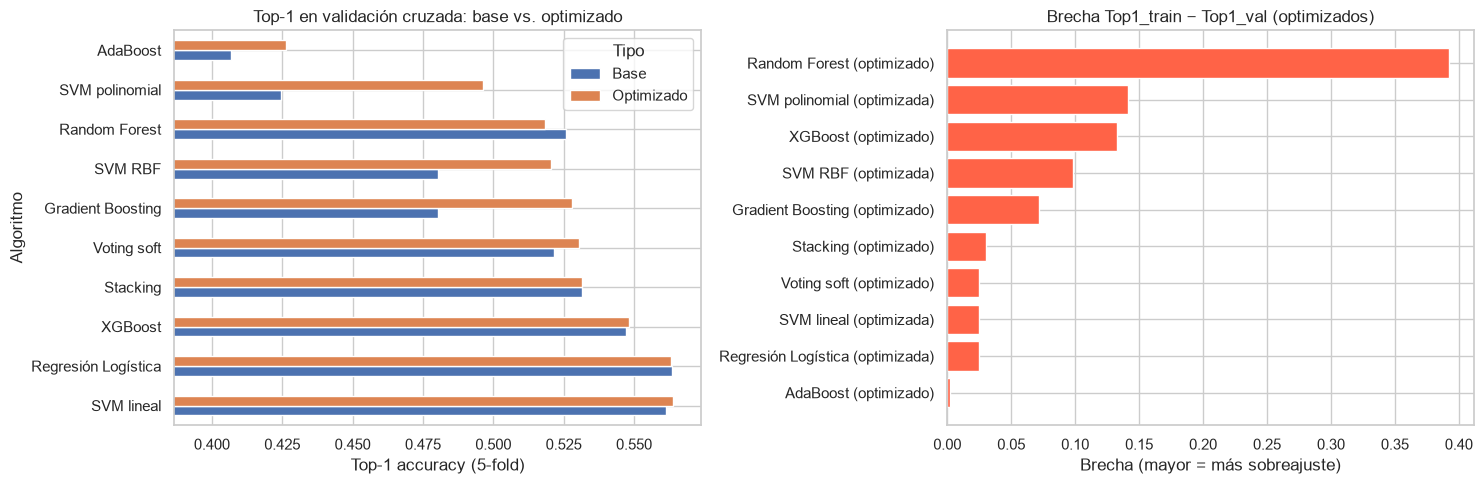

In [30]:
# QUÉ HACE: base vs. optimizado por algoritmo, y brecha de sobreajuste de los modelos optimizados.
t = tabla[tabla["Familia"] != "Referencia"].copy()
t["Algoritmo"] = t["Modelo"].str.replace(r" \((base|optimizad[oa])\)", "", regex=True)
piv = t.pivot_table(index="Algoritmo", columns="Tipo", values="Top1_val").dropna()
piv["Mejora"] = piv["Optimizado"] - piv["Base"]
piv = piv.sort_values("Optimizado", ascending=False)
display(piv.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
piv[["Base", "Optimizado"]].plot.barh(ax=axes[0])
axes[0].set_xlim(piv[["Base", "Optimizado"]].min().min() - 0.02, piv[["Base", "Optimizado"]].max().max() + 0.01)
axes[0].set_title("Top-1 en validación cruzada: base vs. optimizado"); axes[0].set_xlabel("Top-1 accuracy (5-fold)")

opt = tabla[tabla["Tipo"] == "Optimizado"].sort_values("Brecha_top1")
axes[1].barh(opt["Modelo"], opt["Brecha_top1"], color="tomato")
axes[1].set_title("Brecha Top1_train − Top1_val (optimizados)"); axes[1].set_xlabel("Brecha (mayor = más sobreajuste)")
plt.tight_layout(); plt.show()

### Interpretación — comparación general (validación cruzada, 5 folds agrupados por draft)

1. **Los mejores modelos son los lineales:** SVM lineal optimizada (0.5638), Regresión Logística base (0.5635) y optimizada (0.5632), y SVM lineal base (0.5613). Las **4 primeras filas están dentro de 0.0025 y la desviación entre folds es ≈ 0.012–0.014**: *no hay diferencia estadísticamente distinguible* entre ellas. Les sigue XGBoost (0.5482/0.5470) y, más lejos, Stacking/Voting (≈ 0.53), Gradient Boosting (0.528), RBF (0.52), Random Forest (0.52) y polinomial (0.50). AdaBoost es el peor (0.43).
2. **Todos los modelos razonables superan a la línea base de popularidad** (0.452) por entre 6 y 11 puntos de Top-1, y a la de azar (0.171) por mucho más. El Top-3 de los mejores es ≈ 0.88–0.89.
3. **Efecto de la optimización de hiperparámetros:** casi nulo en los modelos lineales (+0.0025 y −0.0003) y en XGBoost (+0.001), pero grande en los que por defecto no están bien configurados: **SVM polinomial +0.072, Gradient Boosting +0.048, SVM RBF +0.040, AdaBoost +0.020**, Voting +0.009. En Random Forest fue ligeramente negativa (−0.007, dentro del ruido). Regla: *cuanto más flexible es el modelo, más importa el ajuste de hiperparámetros*.
4. **Sobreajuste / subajuste** (brecha Top-1 entrenamiento − validación): severo en los **modelos base de Random Forest (0.47), SVM polinomial (0.36), SVM RBF (0.33) y XGBoost (0.28)**; moderado en el Random Forest optimizado (0.39) y XGBoost optimizado (0.13); mínimo en regresión logística y SVM lineal (≈ 0.025). **AdaBoost subajusta** (brecha 0.002 con Top-1 bajo).
5. **Costo vs. beneficio:** la regresión logística base (≈ 35 s) iguala al mejor modelo; el RBF (≈ 41 min) o AdaBoost (≈ 11 min) cuestan mucho más y rinden menos.
6. **Aviso:** las SVM polinomial/RBF usan 2,000 picks; deben compararse con la referencia de regresión logística en esa misma muestra (0.5305), no con los modelos entrenados con 6,000.
7. **Sesgo de selección:** `best_score_` es el máximo entre varias combinaciones y es ligeramente optimista; la evaluación en Test (sección XIII) lo confirma.

## Selección de los 3 mejores modelos

**Regla fijada antes de mirar Test:** entre los modelos **optimizados**, se eligen los **3 con mayor Top-1 medio de validación cruzada**. Serán los que se integren en la aplicación de Streamlit. Si hay empates prácticos (diferencias menores que la desviación entre folds) se documentará, sin cambiar la regla.

In [ ]:
buscadores = {
    "Regresión Logística (optimizada)": bus_lr, "SVM lineal (optimizada)": bus_svm_lin,
    "SVM polinomial (optimizada)": bus_svm_poly, "SVM RBF (optimizada)": bus_svm_rbf,
    "Random Forest (optimizado)": bus_rf, "AdaBoost (optimizado)": bus_ada,
    "Gradient Boosting (optimizado)": bus_gb, "XGBoost (optimizado)": bus_xgb,
    "Voting soft (optimizado)": bus_vot, "Stacking (optimizado)": bus_stk,
}
candidatos = tabla[(tabla["Tipo"] == "Optimizado") & (tabla["Modelo"].isin(buscadores))]
mejores_3 = candidatos.sort_values("Top1_val", ascending=False).head(3)["Modelo"].tolist()
print("Los 3 mejores modelos por Top-1 en validación cruzada:")
for i, m in enumerate(mejores_3, 1):
    f = tabla[tabla["Modelo"] == m].iloc[0]
    print(f"  {i}. {m}  (Top-1={f['Top1_val']:.4f} +-{f['Top1_std']:.4f}, Top-3={f['Top3_val']:.4f}, brecha={f['Brecha_top1']:.4f})")

Los 3 mejores modelos por Top-1 en validación cruzada:
  1. SVM lineal (optimizada)  (Top-1=0.5638 +-0.0143, Top-3=0.8837, brecha=0.0249)
  2. Regresión Logística (optimizada)  (Top-1=0.5632 +-0.0120, Top-3=0.8783, brecha=0.0248)
  3. XGBoost (optimizado)  (Top-1=0.5482 +-0.0147, Top-3=0.8842, brecha=0.1328)


### Interpretación — selección de los 3 mejores modelos

La regla fijada de antemano seleccionó: **SVM lineal (0.5638), Regresión Logística (0.5632) y XGBoost (0.5482)**.

- **Los dos primeros están empatados en la práctica** (diferencia 0.0006 ≪ desviación entre folds de 0.012–0.014). Se mantiene la regla original (cambiarla después de ver resultados contaminaría la evaluación).
- Los tres modelos son **complementarios**: dos lineales (rápidos, estables, brecha 0.025, muy livianos: < 0.1 MB) y un modelo de **boosting** no lineal (brecha mayor, 0.133, pero con el mejor Top-3 y AUC de validación entre los tres: 0.8842 y 0.8776). Esa diversidad es útil en la aplicación, porque permite al usuario comparar un modelo simple y uno más flexible.
- **Despliegue:** los tres pesan menos de 0.3 MB, son rápidos de evaluar y no requieren GPU; las SVM lineales no entregan probabilidades, sino un *puntaje de decisión* (suficiente para ordenar las cartas; la app muestra una versión normalizada dentro del pack).

# XIII. Reentrenamiento final y evaluación en Test

**Reentrenamiento:** los hiperparámetros se eligieron con una muestra de 6,000 picks. Antes de la evaluación final, los 3 modelos seleccionados se **reentrenan con los mismos hiperparámetros** sobre una muestra mayor de Train (`N_PICKS_FINAL` = 30,000 picks): más datos suelen mejorar el rendimiento y no se vuelve a decidir nada con ellos. (Una SVM polinomial o RBF, si resultara seleccionada, conservaría su muestra reducida por su costo cuadrático.)

**Evaluación en Test (primera y única vez que se usa):** sobre **todos los picks de Test** (drafts nunca vistos). Métricas:
- **Top-1 / Top-3 accuracy** por pack y **ROC-AUC** de fila.
- **Accuracy, Precision, Recall, F1 y matriz de confusión** de fila, definiendo la predicción como *"la candidata con mayor puntaje de su pack = positiva; el resto, negativa"*. Como cada pack tiene exactamente un positivo real y un positivo predicho, **Precision = Recall = F1 = Top-1 accuracy**; la matriz de confusión muestra además los falsos positivos/negativos de fila.
- Comparación contra las líneas base (azar, popularidad con tasas de Train, rareza).

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

X_final = muestrear_picks(X_train, N_PICKS_FINAL, semilla=RANDOM_STATE + 1)
print(f"Muestra de reentrenamiento final: {len(X_final):,} candidatas / {X_final['pick_id'].nunique():,} picks")

modelos_finales = {}
for nombre in mejores_3:
    t0 = time.time()
    base = buscadores[nombre].best_estimator_
    if "polinomial" in nombre or "RBF" in nombre:       
        modelos_finales[nombre] = base
    else:
        m = clone(base)
        m.fit(X_final, X_final["y"])
        modelos_finales[nombre] = m
    print(f"  {nombre}: listo ({time.time() - t0:.0f}s)")

def pred_top1_por_pack(X, s):
    d = pd.DataFrame({"pid": X["pick_id"].to_numpy(), "s": np.asarray(s)})
    return (d.groupby("pid")["s"].rank(ascending=False, method="first") == 1).astype(int).to_numpy()

filas, scores_test = [], {}
for nombre, m in modelos_finales.items():
    s = puntaje(m, X_test)
    scores_test[nombre] = s
    y_pred = pred_top1_por_pack(X_test, s)
    filas.append({"Modelo": nombre, "Top-1": topk_desde_puntaje(X_test, s, 1), "Top-3": topk_desde_puntaje(X_test, s, 3),
                  "ROC-AUC": roc_auc_score(y_test, s), "Accuracy (fila)": accuracy_score(y_test, y_pred),
                  "Precision": precision_score(y_test, y_pred), "Recall": recall_score(y_test, y_pred), "F1": f1_score(y_test, y_pred)})
tabla_test = pd.DataFrame(filas).set_index("Modelo")

# Líneas base evaluadas en Test (la popularidad usa SOLO las tasas calculadas con Train)
ale_t = np.random.RandomState(RANDOM_STATE).rand(len(X_test))
base_test = pd.DataFrame({
    "Azar": [topk_desde_puntaje(X_test, ale_t, 1), topk_desde_puntaje(X_test, ale_t, 3)],
    "Popularidad": [topk_desde_puntaje(X_test, X_test["carta"].map(tasa_train).fillna(0), 1),
                    topk_desde_puntaje(X_test, X_test["carta"].map(tasa_train).fillna(0), 3)],
    "Rareza": [topk_desde_puntaje(X_test, X_test["rareza"].to_numpy() + 0.01 * ale_t, 1),
               topk_desde_puntaje(X_test, X_test["rareza"].to_numpy() + 0.01 * ale_t, 3)],
}, index=["Top-1", "Top-3"]).T

print("== Modelos seleccionados en Test ==")
display(tabla_test.round(4))
print("== Líneas base en Test ==")
display(base_test.round(4))

Muestra de reentrenamiento final: 240,024 candidatas / 30,000 picks
  SVM lineal (optimizada): listo (21s)
  Regresión Logística (optimizada): listo (23s)
  XGBoost (optimizado): listo (69s)
== Modelos seleccionados en Test ==


,Top-1,Top-3,ROC-AUC,Accuracy (fila),Precision,Recall,F1
Modelo,,,,,,,
SVM lineal (optimizada),0.5687,0.8886,0.8778,0.8921,0.5687,0.5687,0.5687
Regresión Logística (optimizada),0.5712,0.8898,0.8780,0.8927,0.5712,0.5712,0.5712
XGBoost (optimizado),0.5712,0.8971,0.8876,0.8927,0.5712,0.5712,0.5712


== Líneas base en Test ==


,Top-1,Top-3
Azar,0.1754,0.4826
Popularidad,0.4532,0.8053
Rareza,0.2397,0.5596


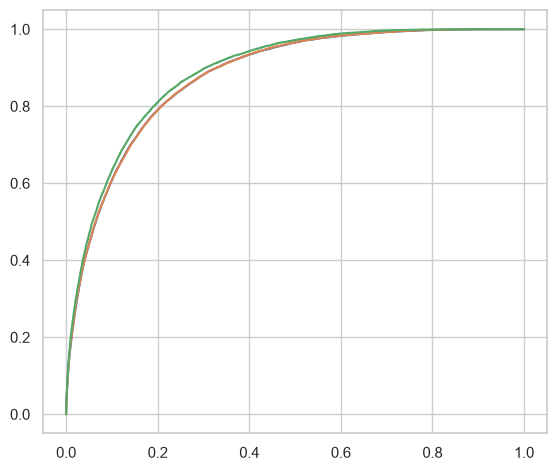

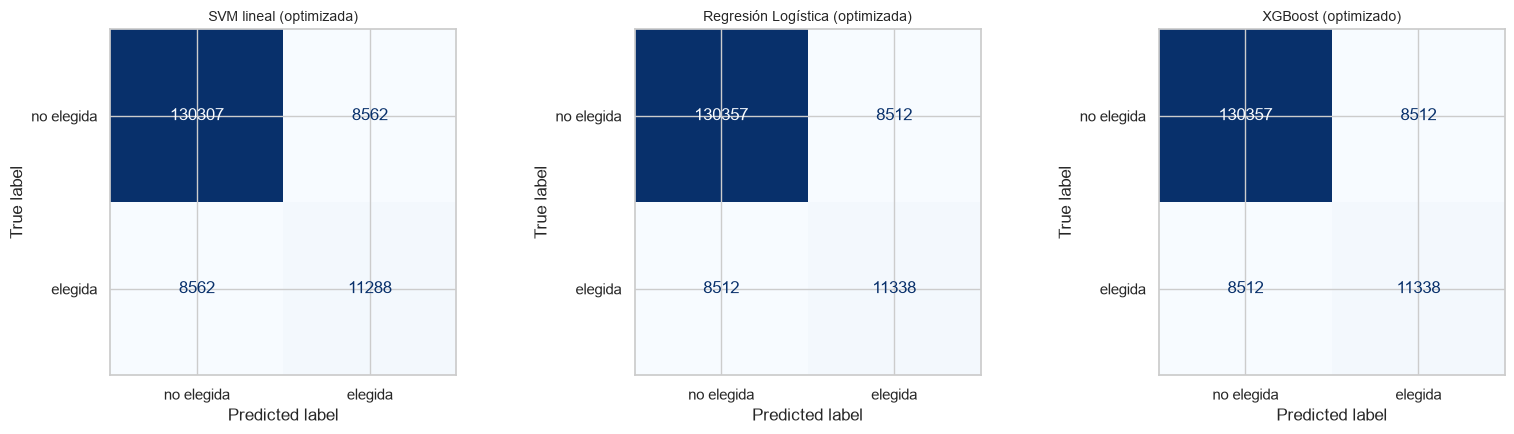

<Figure size 640x480 with 0 Axes>

,Top-1,Top1_cv,Diferencia (Test - CV)
Modelo,,,
SVM lineal (optimizada),0.5687,0.5638,0.0048
Regresión Logística (optimizada),0.5712,0.5632,0.0080
XGBoost (optimizado),0.5712,0.5482,0.0230


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig_roc, ax_roc = plt.subplots(figsize=(6.5, 5.5))
for ax, (nombre, s) in zip(axes, scores_test.items()):
    y_pred = pred_top1_por_pack(X_test, s)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["no elegida", "elegida"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(nombre, fontsize=10)
    fpr, tpr, _ = roc_curve(y_test, s)
    ax_roc.plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, s):.3f})")
plt.figure(fig.number); plt.tight_layout(); plt.show()
ax_roc.plot([0, 1], [0, 1], "k--", label="Azar")
ax_roc.set_xlabel("Tasa de falsos positivos"); ax_roc.set_ylabel("Tasa de verdaderos positivos")
ax_roc.set_title("Curvas ROC en Test (nivel candidata)"); ax_roc.legend(fontsize=8)
plt.figure(fig_roc.number); plt.tight_layout(); plt.show()

# CV (validación) vs Test: ¿generalizan a drafts nunca vistos?
comp = tabla_test[["Top-1"]].join(tabla.set_index("Modelo")["Top1_val"]).rename(columns={"Top1_val": "Top1_cv"})
comp["Diferencia (Test - CV)"] = comp["Top-1"] - comp["Top1_cv"]
display(comp.round(4))

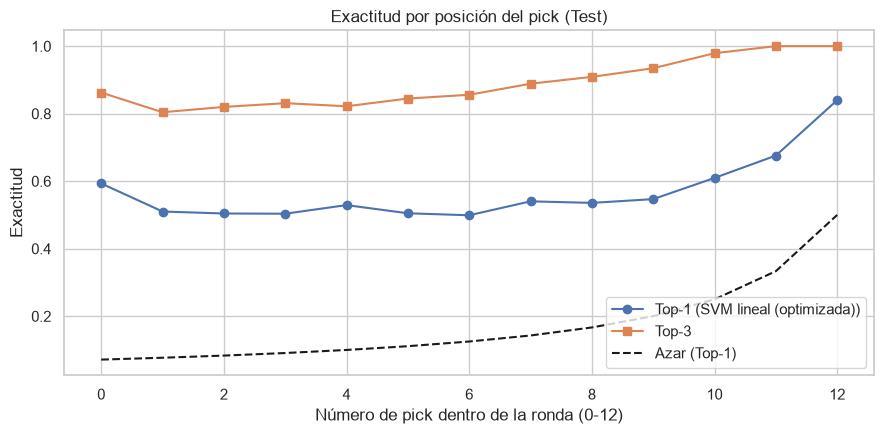

In [ ]:
mejor = mejores_3[0]
d = pd.DataFrame({"pid": X_test["pick_id"].to_numpy(), "s": scores_test[mejor], "y": y_test.to_numpy(),
                  "pick_number": X_test["pick_number"].to_numpy()})
d["rk"] = d.groupby("pid")["s"].rank(ascending=False, method="first")
por_pos = d[d["y"] == 1].groupby("pick_number")["rk"].agg(top1=lambda r: (r <= 1).mean(), top3=lambda r: (r <= 3).mean())
azar_pos = (1 / X_test.drop_duplicates("pick_id").groupby("pick_number")["tam_pack"].mean())

plt.figure(figsize=(9, 4.5))
plt.plot(por_pos.index, por_pos["top1"], marker="o", label=f"Top-1 ({mejor})")
plt.plot(por_pos.index, por_pos["top3"], marker="s", label="Top-3")
plt.plot(azar_pos.index, azar_pos.values, "k--", label="Azar (Top-1)")
plt.xlabel("Número de pick dentro de la ronda (0-12)"); plt.ylabel("Exactitud")
plt.title("Exactitud por posición del pick (Test)"); plt.legend(); plt.tight_layout(); plt.show()

### Interpretación — evaluación final en Test (509 drafts nunca vistos, 19,850 picks)

| Modelo | Top-1 | Top-3 | ROC-AUC |
|---|---|---|---|
| SVM lineal | 0.5687 | 0.8886 | 0.8778 |
| Regresión Logística | 0.5712 | 0.8898 | 0.8780 |
| XGBoost | 0.5712 | **0.8971** | **0.8876** |
| *Línea base: popularidad* | *0.4532* | *0.8053* | — |
| *Línea base: rareza* | *0.2397* | *0.5596* | — |
| *Línea base: azar* | *0.1754* | *0.4826* | — |

1. **Superan con claridad a todas las líneas base.** El mejor Top-1 (0.571) es **+11.8 puntos** sobre popularidad (0.453; +26 % relativo) y **3.3 veces** el del azar (0.175). En Top-3, XGBoost (0.897) supera a popularidad por **+9.2 puntos**. Esto confirma que el modelo no solo "recomienda lo más popular": usa el contexto del pool (colores, curva) para recomendar mejor.
2. **Generalización:** el Top-1 de Test es **igual o superior** al de validación (+0.005, +0.008 y +0.023). No hay sobreajuste en la selección ni diferencia entre Train y Test. La mejora se explica porque los modelos finales se **reentrenaron con 30,000 picks (5 veces más que los 6,000 de la validación cruzada)**: el modelo flexible (XGBoost, +0.023) es el que más se beneficia de más datos, lo que sugiere que con todos los datos de Train podría mejorar un poco más (ver mejoras posibles).
3. **Diferencias entre modelos:** los tres están a menos de 0.3 puntos en Top-1 (empate práctico); XGBoost es mejor en Top-3 (+0.7 puntos) y AUC (+1 punto), es decir, **ordena mejor el conjunto completo de candidatas**, aunque acierta el primer lugar igual.
4. **Métricas de fila (Accuracy, Precision, Recall, F1):** Accuracy de fila = 0.892–0.893, pero **es engañosa**: un modelo que nunca recomendara nada ya tendría 87.5 % por la proporción de clase negativa. Con la definición por pack (una positiva predicha por pack), **Precision = Recall = F1 = Top-1** (0.569–0.571). Para el modelo de regresión logística la matriz de confusión es, aproximadamente: ≈ 11,300 verdaderos positivos (aciertos), ≈ 8,500 falsos positivos (se recomendó otra carta) y el mismo número de falsos negativos (la elegida quedó en 2.º lugar o peor), y ≈ 130,000 verdaderos negativos. El ROC-AUC (≈ 0.88–0.89) indica que, tomando una carta elegida y una no elegida del mismo pack al azar, el modelo puntúa más alto a la elegida ≈ 88–89 % de las veces.
5. **Por posición del pick (gráfica):** el Top-1 es ≈ 0.59 en el primer pick de la ronda, baja a ≈ 0.50 entre los picks 2 y 7 (packs grandes, decisiones difíciles), y sube a ≈ 0.61, 0.68 y 0.84 en los picks 11, 12 y 13, **pero ahí el azar también sube** (0.25, 0.33, 0.50) porque quedan pocas cartas. El modelo supera claramente al azar en **todas** las posiciones. El Top-3 va de ≈ 0.80 a 1.00; en packs con 3 cartas o menos el Top-3 es trivialmente 100 %, por lo que el Top-3 global está **algo inflado** (≈ 15 % de los picks); el Top-1 es la métrica más exigente.

# XIV. Demostración: el asistente recomendando durante un draft completo de Test

Para ver el producto final en acción se toma **un draft de Test** (que el modelo nunca vio) y, pick por pick, se pide la recomendación **con el pool real que el jugador tenía en ese momento** usando la función `recomendar` (la misma que usará la aplicación). Se compara con lo que realmente eligió el jugador.

In [ ]:
mejor_modelo = modelos_finales[mejores_3[0]]
draft_demo = sorted(drafts_test)[0]
filas_demo = picks.index[picks["draft_id"] == draft_demo]
filas_demo = filas_demo[np.array([len(packs[i]) > 1 for i in filas_demo])]

salida = []
for i in filas_demo:
    rec = recomendar(mejor_modelo, catalogo, packs[i], pools[i], int(picks.loc[i, "pack_number"]), int(picks.loc[i, "pick_number"]), k=3)
    real = picks.loc[i, "pick"]
    top3 = rec["carta"].tolist()
    salida.append({"pack": int(picks.loc[i, "pack_number"]) + 1, "pick": int(picks.loc[i, "pick_number"]) + 1,
                   "cartas_en_pack": len(packs[i]), "eligió_el_jugador": real,
                   "recomendación_1": top3[0], "recomendación_2": top3[1] if len(top3) > 1 else "",
                   "recomendación_3": top3[2] if len(top3) > 2 else "",
                   "acierto_top1": real == top3[0], "acierto_top3": real in top3})
demo = pd.DataFrame(salida)
print(f"Draft {draft_demo[:8]}...: top-1 = {demo['acierto_top1'].mean():.2f} | top-3 = {demo['acierto_top3'].mean():.2f}")
demo.head(12)

Draft 00553658...: top-1 = 0.56 | top-3 = 0.90


,pack,pick,cartas_en_pack,eligió_el_jugador,recomendación_1,recomendación_2,recomendación_3,acierto_top1,acierto_top3
0,1,1,14,Sanctum Lurker,Sanctum Lurker,"Vraska, the Cutting Glare",Violent Echoes,True,True
1,1,2,13,Theorist's Sanctum,Theorist's Sanctum,Void Extrapolator,Surgical Precision,True,True
2,1,3,12,Surveillance Phantasm,Last Gasp,Prophesied End,Cast Away Doubt,False,False
3,1,4,11,Mind Meanderer,"Arni, Humble Scribe",Way of the Healer,Mind Meanderer,False,True
4,1,5,10,Sphinx's Approach,"Arni, Humble Scribe",Arcane Amphisbaena,Sphinx's Approach,False,True
5,1,6,9,Fatehold Chronologist,Theorix Charm,Fatehold Chronologist,Fatehold Annex,False,True
6,1,7,8,Theorix Metamage,Way of the Cryomancer,Sphinx's Approach,Unflinching Hortimancer,False,False
7,1,8,7,Innovative Commons,Fatehold Charm,"Yuriko, Hope from the Shadows",Innovative Commons,False,True
8,1,9,6,Bloombrute,Bloombrute,Room of Refuge,Divining Duelist,True,True
9,1,10,5,Void Extrapolator,Perfected Theory,Academic Ascent,Void Extrapolator,False,True


### Interpretación — draft de demostración

En el draft de Test elegido, el asistente acertó el **Top-1 en el 56 %** de los picks y el **Top-3 en el 90 %**, cifras cercanas a las de Test completo (57 % y 89–90 %), como se espera. En los dos primeros picks recomendó exactamente la carta que eligió el jugador; en otros (por ejemplo los picks 3 a 8), la carta real quedó 2.ª o 3.ª. Cuando el jugador elige algo distinto de la mejor recomendación, la elegida suele estar entre las 3 primeras, que es justo lo que muestra la aplicación: **no se pretende adivinar un único pick, sino ofrecer 2-3 buenas opciones**. Un solo draft no es una medida de desempeño (la medida son las métricas de Test); sirve para ver el comportamiento del asistente con el pool real que el jugador iba teniendo.

## Exportación de los modelos para la aplicación de Streamlit

Se guarda, con `joblib`, cada **Pipeline completo** (preprocesamiento + clasificador), el **catálogo de cartas** (metadatos y vocabulario) y los metadatos. El módulo `draft_utils.py` (escrito en la sección 3.1) debe acompañar a estos archivos: la aplicación importa de él `construir_features`, `recomendar` y `resolver_nombres`.

In [36]:
# QUÉ HACE: guarda los 3 modelos finales (Pipeline completo), el catálogo y los metadatos en la carpeta modelos_streamlit/.
# En la app: modelo = joblib.load("modelos_streamlit/modelo_1.joblib").
# IMPORTANTE: usar en la app las mismas versiones de scikit-learn / xgboost que en este notebook.
import os, joblib, sklearn

os.makedirs("modelos_streamlit", exist_ok=True)
for i, nombre in enumerate(mejores_3, 1):
    ruta = f"modelos_streamlit/modelo_{i}.joblib"
    joblib.dump(modelos_finales[nombre], ruta, compress=3)
    print(f"{nombre} -> {ruta} ({os.path.getsize(ruta) / 1e6:.1f} MB)")

joblib.dump(catalogo, "modelos_streamlit/catalogo.joblib", compress=3)
joblib.dump({"nombres_modelos": mejores_3, "metricas_test": tabla_test.round(4).to_dict(),
             "version_sklearn": sklearn.__version__}, "modelos_streamlit/metadatos.joblib")
print("\nArchivos en modelos_streamlit/:", os.listdir("modelos_streamlit"))
print("Versión de scikit-learn:", sklearn.__version__)

SVM lineal (optimizada) -> modelos_streamlit/modelo_1.joblib (0.0 MB)
Regresión Logística (optimizada) -> modelos_streamlit/modelo_2.joblib (0.0 MB)
XGBoost (optimizado) -> modelos_streamlit/modelo_3.joblib (0.2 MB)

Archivos en modelos_streamlit/: ['catalogo.joblib', 'metadatos.joblib', 'modelo_1.joblib', 'modelo_2.joblib', 'modelo_3.joblib']
Versión de scikit-learn: 1.9.0


# XVI. Comparación con la literatura

**Trabajos relacionados** (localizados mediante búsqueda en arXiv; se citan solo cifras verificables en sus resúmenes/tablas):

- **Bertram, Fürnkranz y Müller (2024)** abordan **la misma tarea de fondo: predecir la carta que elige un jugador humano en el draft**, comparando distintas representaciones generalizadas de carta, con ≈ 100 millones de picks. Según su resumen, su modelo generalizado acierta **55 % de las elecciones humanas en cartas completamente nuevas** (sets no vistos); en su tabla de resultados reportan ≈ **66.5 %** en datos retenidos de sets ya vistos con el modelo preentrenado. Estas cifras son la referencia más directa del orden de magnitud de la tarea.
- **Rigaux y Kashima (2026)** estudian la predicción de la **fuerza de un mazo drafteado** con *embeddings* de carta dependientes del set; es un problema relacionado (valor del pool), no de recomendación de pick, y es la base del modelo de respaldo de este proyecto (predicción del resultado del *run*).
- **17Lands** publica los datos y estadísticas por carta que muchos jugadores usan como "tier list" empírica; la **línea base de popularidad** de este notebook es la versión más simple de esa idea.

**Comparación con este proyecto.** Los resultados obtenidos aquí — **Top-1 ≈ 57 % y Top-3 ≈ 89–90 % en Test** — quedan en el mismo orden de magnitud que el ≈ 66.5 % de Bertram et al. en sets vistos, **sin ser una comparación equivalente**:

| Aspecto | Bertram et al. (2024) | Este proyecto |
|---|---|---|
| Datos | ≈ 100 millones de picks, muchos sets | ≈ 107 mil picks (se usan 30 mil para el modelo final), un solo set |
| Jugadores | (no verificado) | Solo jugadores con win rate ≥ 0.58 |
| Modelo | Modelo preentrenado con representaciones de carta | Modelos clásicos de scikit-learn con variables diseñadas a mano |
| Métrica | Exactitud de elección (Top-1) | Top-1 y Top-3 por pack, ROC-AUC |

Con **≈ 0.1 % de los datos** y modelos mucho más simples, se logra un Top-1 que no está lejos de lo reportado con entrenamiento masivo, y supera con claridad a las líneas base. Es razonable esperar que el desempeño aumente con más datos: el propio resultado de este proyecto lo sugiere (la regresión logística pasa de 0.53 a 0.56 al triplicar los picks, y XGBoost gana +2.3 puntos entre validación y Test al pasar de 6,000 a 30,000 picks). Además, los **jugadores fuertes** son más consistentes que el promedio, lo que puede ayudar o perjudicar la comparación según cómo estén repartidos los datos de cada trabajo.

# XVII. Conclusiones

**Pregunta del proyecto:** ¿puede construirse un asistente que, dado un pack y el pool actual, recomiende las mejores cartas? **Sí.** Los mejores modelos aciertan la carta que eligió un jugador fuerte en **primer lugar el ≈ 57 %** de las veces y dentro de las **3 primeras recomendaciones el ≈ 89–90 %** (Test, 509 drafts nunca vistos), frente al 17.5 % / 48.3 % del azar y al 45.3 % / 80.5 % de la heurística de popularidad.

**1. Hallazgos del EDA.** La identidad de la carta es muy informativa: la tasa de elección va de ≈ 0.1 % (terrenos básicos) a > 90 % (*Ajani Unrelenting*). La rareza se asocia con la elección (común ≈ 11 % → mítica ≈ 38 %), los Planeswalkers se eligen ≈ 58 % de las veces y el azul es el color más elegido (≈ 18 %). Los jugadores se comprometen con 2 colores muy pronto (≈ 84 % del pool en 2 colores hacia el pick 6), aunque la proporción baja a ≈ 76 % al final del draft. El tamaño del pack baja de 14 a 1, por lo que el azar acierta cada vez más hacia el final de cada ronda.

**2. Impacto del preprocesamiento y la ingeniería de variables.** Convertir cada pick en filas de cartas candidatas con variables de **encaje carta–pool** (afinidad de color, curva de maná, copias) fue la decisión clave: `afinidad_color_media`, `en_top2_colores` y `rareza_rank_pack` encabezan la importancia/los coeficientes. La **partición y la validación por draft** evitan la fuga de información entre picks correlacionados, y escalado/One-Hot dentro del `Pipeline` evitan fuga desde la validación. No se midió con un experimento aislado la contribución de cada transformación; se afirma su necesidad metodológica, no una ganancia cuantificada.

**3. Diferencias entre algoritmos.** Los modelos **lineales** (regresión logística y SVM lineal) lideran la validación (Top-1 ≈ 0.563); XGBoost es el único no lineal competitivo (0.548, mejor en Top-3/AUC); Stacking y Voting (≈ 0.53), Gradient Boosting (0.528), SVM RBF (0.52), Random Forest (0.52), SVM polinomial (0.50) y AdaBoost (0.43) quedan por debajo. Entre los 4 primeros la diferencia (≤ 0.0025) es menor que la desviación entre folds (≈ 0.013). Los modelos no lineales no ganan porque **las interacciones ya están codificadas** en las variables de encaje; y los ensambles heterogéneos no ayudan porque mezclan al mejor modelo (lineal) con otros más débiles.

**4. Efecto de la optimización de hiperparámetros.** Casi nulo en modelos ya bien regularizados por defecto (regresión logística, SVM lineal, XGBoost: ≤ +0.0025) y grande en modelos que por defecto no son adecuados (**SVM polinomial +0.072, Gradient Boosting +0.048, SVM RBF +0.040, AdaBoost +0.020**); además redujo el sobreajuste (p. ej. brecha de XGBoost 0.28 → 0.13). En Random Forest no mejoró el Top-1 (−0.007, ruido).

**5. Selección de los mejores modelos.** Se eligieron, con la regla fijada de antemano, **SVM lineal, Regresión Logística y XGBoost** (los dos primeros empatados en la práctica). En Test obtuvieron Top-1 = 0.569 / 0.571 / 0.571, Top-3 = 0.889 / 0.890 / 0.897 y ROC-AUC = 0.878 / 0.878 / 0.888. Se recomienda la **Regresión Logística** como modelo principal (simple, rápida, interpretable, mejor relación costo/beneficio) y **XGBoost** como alternativa no lineal (mejor Top-3 y AUC). Resultados consistentes con validación (Test ≥ CV), sin indicios de sobreajuste en la selección.

**6. Limitaciones.**
- El modelo **imita a jugadores fuertes**; no optimiza el resultado de las partidas ni garantiza la mejor decisión. Si los jugadores fuertes comparten un sesgo, el modelo lo hereda.
- **No ve la información de la mesa** (qué cartas pasaron los oponentes, colores "abiertos"), ni cuántos picks del mismo color se perdieron antes; solo ve el pack actual y el pool propio.
- **Los terrenos básicos** casi nunca se eligen y son candidatas "fáciles"; junto con los packs de ≤ 3 cartas (Top-3 trivial) **inflan ligeramente** las métricas por pack, sobre todo el Top-3. El Top-1 en los picks 2 a 7 (≈ 0.50) es la medida más representativa de la dificultad real.
- **Un solo set (Reality Fracture) en su primer mes de vida:** el metajuego evoluciona y los jugadores aún están descubriendo qué es fuerte; el modelo no generaliza a sets nuevos sin reentrenar (la identidad de carta es una variable central).
- 10 cartas con metadatos completados por nombre (pertenecen a otros sets); si hubiera cartas sin datos de Scryfall, se les asignan valores neutros.
- Se usó una muestra de 6,000 picks para optimizar hiperparámetros y de 2,000 para SVM no lineal (por costo). Varios hiperparámetros óptimos quedaron en el borde de la rejilla (`C = 1` en regresión logística, `gamma = 0.0003` en RBF, `max_depth`/`min_samples_leaf` en Random Forest, `learning_rate` en AdaBoost).
- Una sola partición Train/Test y una sola semilla; no se reportan intervalos de confianza de Test.

**7. Posibles mejoras.** (a) Entrenar los modelos finales con **todo Train** (≈ 79 mil picks) o con más drafts (`--draft-sample` mayor): XGBoost mostró que se beneficia de más datos. (b) Variables de **sinergia entre cartas** (co-ocurrencia en los pools de jugadores exitosos, *embeddings* de carta) y uso del **texto** de las cartas. (c) Tasas de victoria por carta de 17Lands (*GIH WR*) calculadas solo con Train. (d) Modelar la **información de la mesa** (señales de colores abiertos). (e) Combinar la recomendación con el **modelo de respaldo** de predicción del resultado del run (valor esperado del mazo). (f) Ampliar rejillas de hiperparámetros en los bordes, y reportar intervalos de confianza por *bootstrap* de drafts.

# XVIII. Referencias

- Rigaux, T., & Kashima, H. (2026). Predicting Drafted Deck Strength for "Magic: the Gathering". arXiv:2607.04782. https://arxiv.org/abs/2607.04782
- 17Lands. *Public datasets* (draft data, FRA — Reality Fracture, Premier Draft). https://www.17lands.com/public_datasets
- Scryfall. *Scryfall API Documentation*. https://scryfall.com/docs/api
